# table of contents

1. [Pearson vs. Spearman Correlation](#pearson-vs-spearman-correlation)
2. [Partial Correlation](#partial-correlation)
3. [Advanced Correlation Analysis](#Advanced-Correlation-Analysis)

### Pearson vs. Spearman Correlation 

### 1.  Dataset
- Core Focus
    * Fundamental concepts of correlation, Pearson correlation, and Spearman's rank correlation.
- Dataset Used
    * The Palmer Penguins dataset collected by Dr. Kristen Gorman.
    * Sample Size: 344 total observations, resulting in 333 complete observations after dropping missing values.
    * Continuous Variables: Bill length (mm), bill depth (mm), flipper length (mm), and body mass (g).
    * Categorical / Non-Continuous Variables: Penguin species (Adelie, Chinstrap, Gentoo), island (Torgersen, Biscoe, Dream), and sex (male, female).

### 2. Core Concepts of Correlation
- Definition
    * Measures the strength and direction of a relationship between two variables.
- Properties
    * Range: Values range strictly from -1.0 to +1.0.
    * Direction: Positive correlation means both variables increase together; negative (inverse) correlation means one variable increases as the other decreases.
- Scale Interpretation
    * $+1.0$: Perfect positive correlation.
    * $0.0$: No linear correlation.
    * $-1.0$: Perfect negative correlation.
- Golden Rule
    * Correlation does not imply causation.

### 3. Pearson Correlation vs. Spearman Rank Correlation

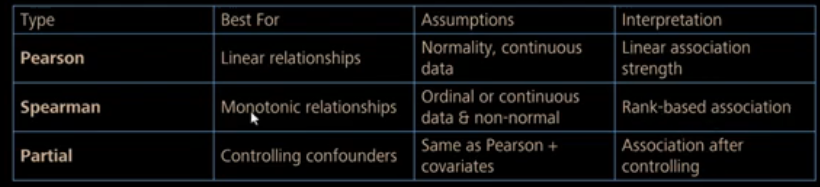

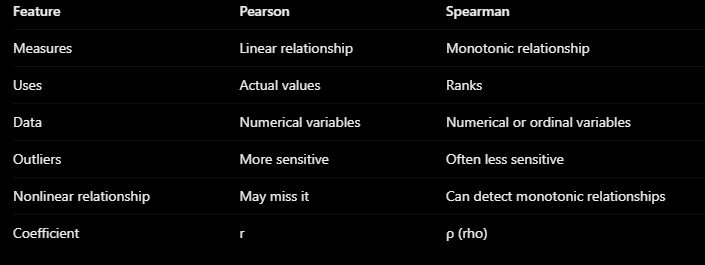



#### Pearson Correlation Coefficient ($r$)
- Purpose
    * Measures the strength and direction of a linear relationship between two continuous variables.
- Mathematical Formula
    $$r = \frac{\sum (X - \bar{X})(Y - \bar{Y})}{\sqrt{\sum (X - \bar{X})^2 \sum (Y - \bar{Y})^2}}$$
    * Where $\bar{X}$ and $\bar{Y}$ represent the sample means of variables $X$ and $Y$.
- Core Assumptions
    1. Continuous Data: Both variables must be continuous numerical measurements.
    2. Linearity: The underlying relationship between variables must be linear.
    3. Bivariate Normality: Both variables must be normally distributed.
    4. Homoscedasticity: The variance of the residuals must remain constant across all fitted values.
    5. Independence of Observations: Each pair of data points must be independent.
    6. No Extreme Outliers: Outliers can disproportionately distort the correlation coefficient.

#### Spearman Rank Correlation Coefficient ($\rho$ or Row)
- Purpose
    * Measures the strength and direction of a monotonic relationship (whether variables move in the same relative direction, even if non-linearly).
- When to Use
    * Used when Pearson assumptions fail—specifically for non-normal continuous data, ordinal data, non-linear relationships, or datasets containing outliers.
- Mechanism
    * Converts raw data values into numerical ranks (1st, 2nd, 3rd place) and computes the correlation on the assigned ranks.
- Handling Ties
    * Automatically handles tied values by assigning the average rank (e.g., two tied values for 2nd place both receive a rank of 2.5).

### 4. Diagnostic Tests & Checking Assumptions in Python

- Normality Testing
    * Method: Evaluated using the Shapiro-Wilk test (`scipy.stats.shapiro`) alongside visual inspection via histograms, Q-Q plots, and box plots.
    * Hypothesis Decision:
        - Null Hypothesis ($H_0$): The dataset is normally distributed.
        - If $p < 0.05$, $H_0$ is disproved, confirming the data is non-normal.
    * Palmer Penguins Outcome: All four continuous variables yielded $p < 0.05$ in formal Shapiro-Wilk testing, indicating non-normality; however, visual Q-Q and histogram plots showed bill length, flipper length, and body mass were near-normal, while bill depth exhibited a bimodal profile.

- Linearity Testing
    * Method: Fits both a 1st-degree polynomial (linear) and a 2nd-degree polynomial (quadratic) regression model to the data.
    * Evaluation Metric: Computes the improvement in $R^2$ ($R^2_{\text{quadratic}} - R^2_{\text{linear}}$).
    * Threshold: If the $R^2$ improvement is $< 0.05$ (5%), the additional quadratic term offers negligible benefit, satisfying the linearity assumption.

- Homoscedasticity Testing (Simplified Breusch-Pagan Check)
    * Method: Fits a linear model, extracts absolute residuals ($|Y - Y_{\text{fitted}}|$), and performs a Pearson test between the absolute residuals and the fitted values.
    * Threshold: A $p$-value $> 0.05$ indicates no significant correlation between residuals and fitted values, confirming equal variance (homoscedasticity).

- Outlier Detection
    * Univariate Outliers: Identified via $Z$-scores (values beyond $\pm 3\sigma$ from the mean) or interquartile ranges.
    * Bivariate Outliers: Evaluated using Mahalanobis Distance, which measures how far a 2D data point lies from the dataset center using the covariance matrix. Points exceeding the Chi-Square ($\chi^2$) critical value at a 99.9% confidence level are flagged as bivariate outliers.

### 5. Python Implementation & Comparative Results

- Primary Python Functions
    * Pandas Built-in: `df.corr(method='pearson')` and `df.corr(method='spearman')` generate complete correlation matrices.
    * SciPy Functions: `scipy.stats.pearsonr(x, y)` and `scipy.stats.spearmanr(x, y)` return both the correlation coefficient ($r$ or $\rho$) and the corresponding two-tailed $p$-value.

- Key Results on Palmer Penguins Data
    * Flipper Length vs. Body Mass:
        - Pearson $r \approx 0.589$.
        - Spearman $\rho \approx 0.576$.
    * Pearson vs. Spearman Agreement: Plotting Pearson coefficients against Spearman coefficients across all feature pairs produces a near-straight diagonal line, proving that minor deviations from normality do not prevent Pearson from agreeing closely with Spearman.
    * Confounding Variable Preview: Splitting data by species reveals distinct clusters (e.g., bill length and depth vary significantly across Adelie, Chinstrap, and Gentoo), highlighting the need for partial correlation to control for species as a confounder in subsequent analysis.

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import pearsonr, spearmanr, kendalltau
import statsmodels.api as sm
from statsmodels.stats.correlation_tools import corr_nearest, corr_clipped
import warnings
from itertools import combinations
import requests
from io import StringIO

from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.linear_model import LinearRegression


from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import squareform
from statsmodels.stats.multitest import multipletests
from sklearn.utils import resample
import math


In [2]:
# Suppress warnings for cleaner output
warnings.filterwarnings('ignore')

# Set visualization style consistent with previous tutorials
sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 12

In [3]:
# Load palmer penguin dataset from online source
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"

penguins = pd.read_csv(url)


# Display basic information about the dataset
print("\nDataset Information:")
print("=" * 25)
print(f"Shape: {penguins.shape}")
print(f"Columns: {list(penguins.columns)}")


Dataset Information:
Shape: (344, 7)
Columns: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']


In [4]:

# Check for missing values
print("\nMissing values per column:")
missing_counts = penguins.isnull().sum()
for col, count in missing_counts.items():
    print(f"  {col}: {count}")

# Remove rows with missing values for correlation analysis
penguins_clean = penguins.dropna()
print(f"\nAfter removing missing values: {penguins_clean.shape[0]} complete observations")


Missing values per column:
  species: 0
  island: 0
  bill_length_mm: 2
  bill_depth_mm: 2
  flipper_length_mm: 2
  body_mass_g: 2
  sex: 11

After removing missing values: 333 complete observations


In [5]:
# Define continuous variables for correlation analysis
continuous_vars = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
categorical_vars = ['species', 'island', 'sex']

### 1. Introduction to correlation analysis

#### * The Coefficient of Variation (CV) tells us how much variation there is in a variable compared with its own average (mean).
* $CV = (standard Deviation / mean ) * 100$
* less variation - closer to avg , data is more consistent.
* more variation - more spread form avg , data is less consistent.


EXPLORATORY DATA ANALYSIS FOR CORRELATION

Descriptive Statistics for Continuous Variables:
--------------------------------------------------
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count          333.00         333.00             333.00       333.00
mean            43.99          17.16             200.97      4207.06
std              5.47           1.97              14.02       805.22
min             32.10          13.10             172.00      2700.00
25%             39.50          15.60             190.00      3550.00
50%             44.50          17.30             197.00      4050.00
75%             48.60          18.70             213.00      4775.00
max             59.60          21.50             231.00      6300.00

Coefficient of Variation (CV = std/mean):
----------------------------------------
bill_length_mm      :   12.4%
bill_depth_mm       :   11.5%
flipper_length_mm   :    7.0%
body_mass_g         :   19.1%

Normality Assessment (Shapiro-

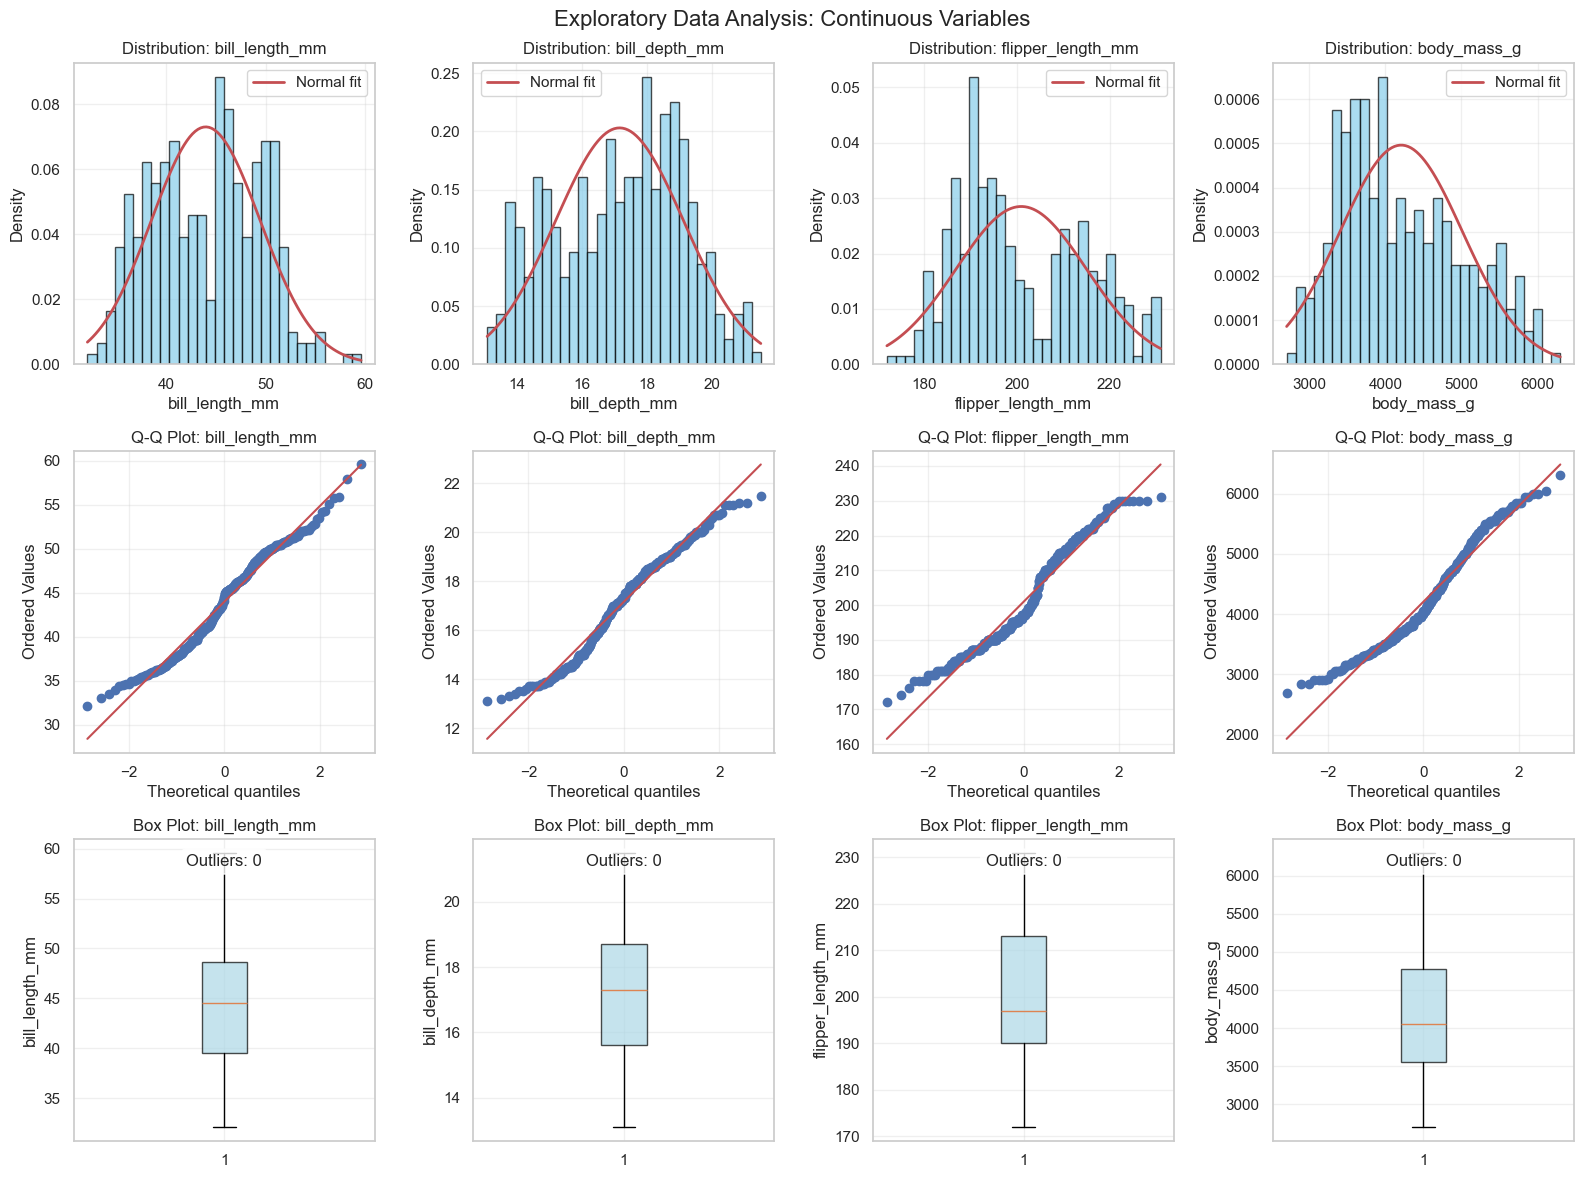


Outlier Analysis:
--------------------
bill_length_mm      :   0 outliers (  0.0%)
bill_depth_mm       :   0 outliers (  0.0%)
flipper_length_mm   :   0 outliers (  0.0%)
body_mass_g         :   0 outliers (  0.0%)

Species-specific Means:
-------------------------
           bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
species                                                                 
Adelie              38.82          18.35             190.10      3706.16
Chinstrap           48.83          18.42             195.82      3733.09
Gentoo              47.57          15.00             217.24      5092.44


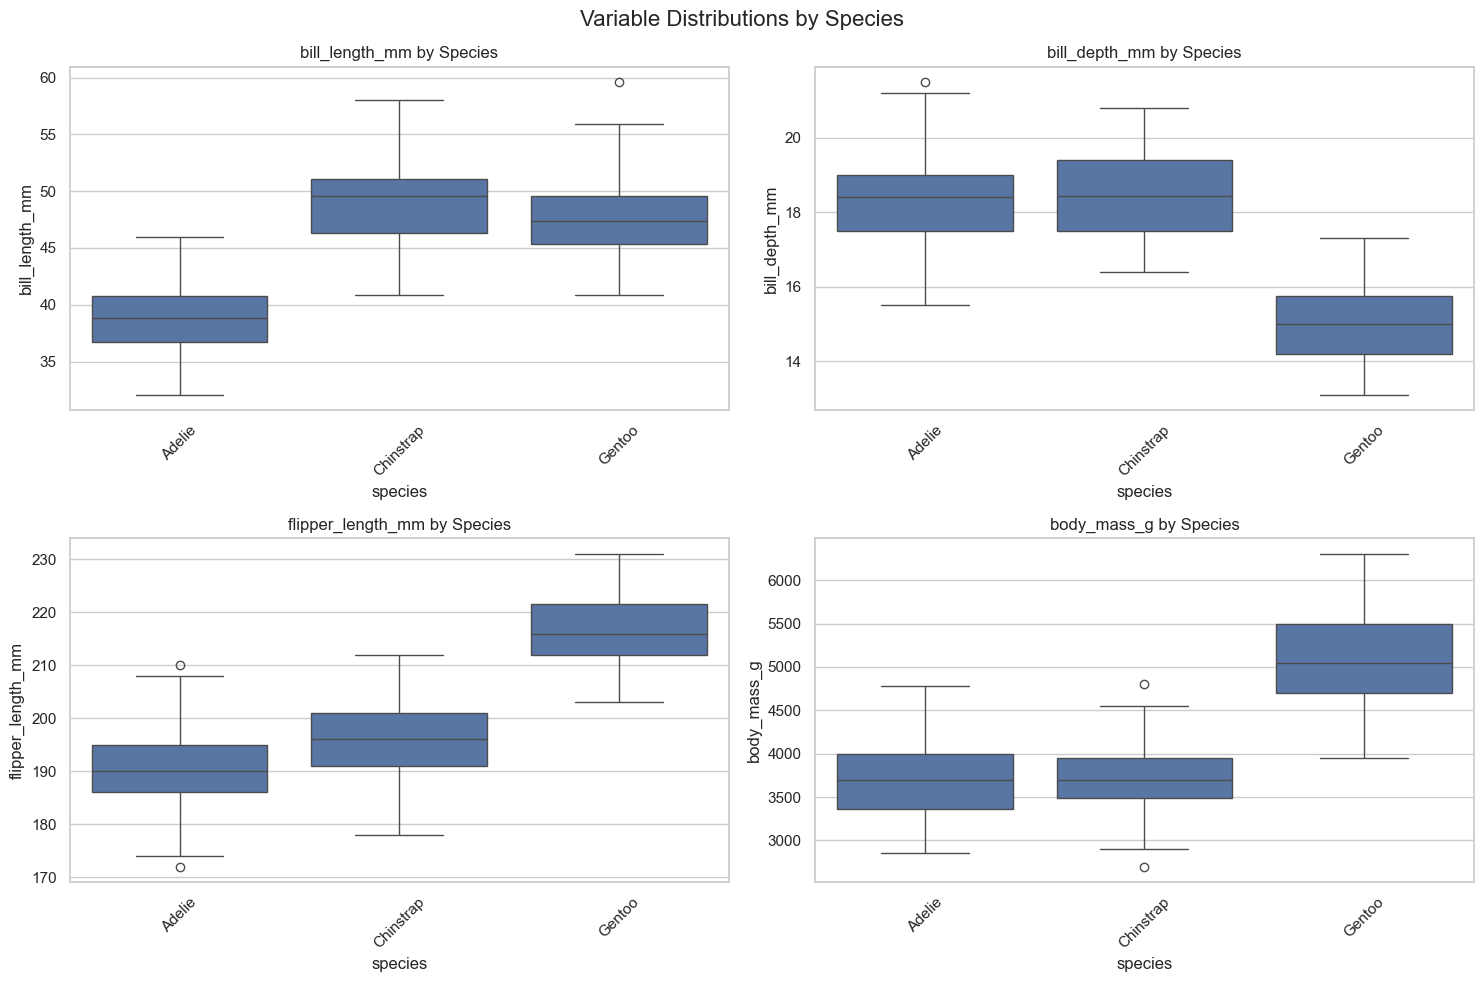

In [6]:
def explore_correlation_data(data, continuous_vars):
    """
    Exploration of the dataset focusing on relationships between continuous variables.

    """
    print("\n" + "=" * 70)
    print("EXPLORATORY DATA ANALYSIS FOR CORRELATION")
    print("=" * 70)

    # Basic descriptive statistics
    print("\nDescriptive Statistics for Continuous Variables:")
    print("-" * 50)

    desc_stats = data[continuous_vars].describe().round(2)
    print(desc_stats)

    # Calculate coefficient of variation for each variable
    # Remember that CV helps to understand the extent of dispersion or variability around the mean of a dataset.
    print(f"\nCoefficient of Variation (CV = std/mean):")
    print("-" * 40)
    for var in continuous_vars:
        mean_val = data[var].mean()
        std_val = data[var].std()
        cv = (std_val / mean_val) * 100
        print(f"{var:<20}: {cv:>6.1f}%")

    # Check distributions for normality (important for Pearson correlation)
    print(f"\nNormality Assessment (Shapiro-Wilk Test):")
    print("-" * 45)
    normality_results = {}

    for var in continuous_vars:
        # Use sample if data is too large for Shapiro-Wilk
        sample_data = data[var].dropna()
        if len(sample_data) > 5000:
            sample_data = sample_data.sample(5000, random_state=42)

        stat, p_value = stats.shapiro(sample_data)
        normality_results[var] = {'statistic': stat, 'p_value': p_value}

        interpretation = "Normal" if p_value > 0.05 else "Non-normal"
        print(f"{var:<20}: W = {stat:.4f}, p = {p_value:.4f} ({interpretation})")

    # Create different visualizations
    n_vars = len(continuous_vars)
    fig, axes = plt.subplots(3, n_vars, figsize=(4*n_vars, 12))
    fig.suptitle('Exploratory Data Analysis: Continuous Variables', fontsize=16)

    for i, var in enumerate(continuous_vars):
        var_data = data[var].dropna()

        # Row 1: Histograms with normal overlay
        axes[0, i].hist(var_data, bins=30, density=True, alpha=0.7,
                       color='skyblue', edgecolor='black')

        # Overlay normal distribution
        mu, sigma = stats.norm.fit(var_data)
        x = np.linspace(var_data.min(), var_data.max(), 100)
        axes[0, i].plot(x, stats.norm.pdf(x, mu, sigma), 'r-',
                       linewidth=2, label='Normal fit')

        axes[0, i].set_title(f'Distribution: {var}')
        axes[0, i].set_xlabel(var)
        axes[0, i].set_ylabel('Density')
        axes[0, i].legend()
        axes[0, i].grid(True, alpha=0.3)

        # Row 2: Q-Q plots for normality
        stats.probplot(var_data, dist="norm", plot=axes[1, i])
        axes[1, i].set_title(f'Q-Q Plot: {var}')
        axes[1, i].grid(True, alpha=0.3)

        # Row 3: Box plots
        axes[2, i].boxplot(var_data, patch_artist=True,
                          boxprops=dict(facecolor='lightblue', alpha=0.7))
        axes[2, i].set_title(f'Box Plot: {var}')
        axes[2, i].set_ylabel(var)
        axes[2, i].grid(True, alpha=0.3)

        # Add outlier information
        Q1 = var_data.quantile(0.25)
        Q3 = var_data.quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        outliers = var_data[(var_data < lower_bound) | (var_data > upper_bound)]

        axes[2, i].text(0.5, 0.95, f'Outliers: {len(outliers)}',
                       transform=axes[2, i].transAxes, ha='center', va='top',
                       bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    plt.tight_layout()
    plt.show()

    # Identify potential outliers
    print(f"\nOutlier Analysis:")
    print("-" * 20)

    outlier_summary = {}
    for var in continuous_vars:
        var_data = data[var].dropna()
        Q1 = var_data.quantile(0.25)
        Q3 = var_data.quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = var_data[(var_data < lower_bound) | (var_data > upper_bound)]
        outlier_percentage = (len(outliers) / len(var_data)) * 100

        outlier_summary[var] = {
            'count': len(outliers),
            'percentage': outlier_percentage,
            'lower_bound': lower_bound,
            'upper_bound': upper_bound
        }

        print(f"{var:<20}: {len(outliers):>3} outliers ({outlier_percentage:>5.1f}%)")

    # Species-specific analysis
    if 'species' in data.columns:
        print(f"\nSpecies-specific Means:")
        print("-" * 25)
        species_means = data.groupby('species')[continuous_vars].mean().round(2)
        print(species_means)

        # Visualize species differences
        fig, axes = plt.subplots(2, 2, figsize=(15, 10))
        fig.suptitle('Variable Distributions by Species', fontsize=16)

        for i, var in enumerate(continuous_vars):
            row = i // 2
            col = i % 2

            sns.boxplot(data=data, x='species', y=var, ax=axes[row, col])
            axes[row, col].set_title(f'{var} by Species')
            axes[row, col].tick_params(axis='x', rotation=45)

        plt.tight_layout()
        plt.show()

    return {
        'descriptive_stats': desc_stats,
        'normality_results': normality_results,
        'outlier_summary': outlier_summary,
        'species_means': species_means if 'species' in data.columns else None
    }

# Step 1: Explore the data
exploration_results = explore_correlation_data(penguins_clean, continuous_vars)
     

### Correlation concepts- visual demonstration


CORRELATION CONCEPTS: VISUAL DEMONSTRATION


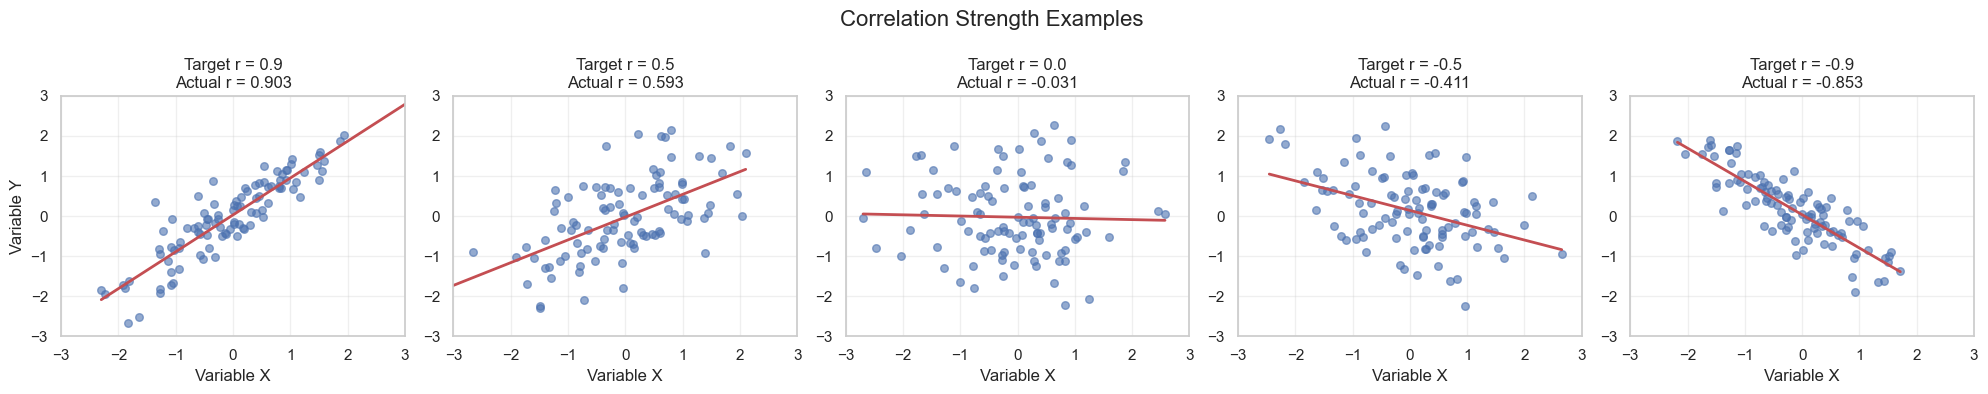


Correlation Interpretation Guide:
-----------------------------------
Perfect positive (r = +1.0)   : Y increases exactly as X increases
Strong positive (r = +0.7 to +0.9): Y tends to increase as X increases
Moderate positive (r = +0.3 to +0.7): Y somewhat increases as X increases
Weak (r = -0.3 to +0.3)       : Little to no linear relationship
Moderate negative (r = -0.7 to -0.3): Y somewhat decreases as X increases
Strong negative (r = -0.9 to -0.7): Y tends to decrease as X increases
Perfect negative (r = -1.0)   : Y decreases exactly as X increases


In [8]:
def demonstrate_correlation_concepts():
    """
    Demonstrate correlation concepts with simulated examples to build intuition.
    We will then look at our penguin dataset
    """
    print("\n" + "=" * 70)
    print("CORRELATION CONCEPTS: VISUAL DEMONSTRATION")
    print("=" * 70)

    # Generate example data with different correlation strengths
    np.random.seed(42)
    n = 100
    x = np.random.normal(0, 1, n)

    # Create different correlation scenarios
    correlations = [0.9, 0.5, 0.0, -0.5, -0.9]
    correlation_data = {}

    for r in correlations:
        # Generate correlated data using Cholesky decomposition
        cov_matrix = np.array([[1, r], [r, 1]])
        data_pair = np.random.multivariate_normal([0, 0], cov_matrix, n)
        correlation_data[r] = {'x': data_pair[:, 0], 'y': data_pair[:, 1]}

    # Create visualization
    fig, axes = plt.subplots(1, len(correlations), figsize=(20, 4))
    fig.suptitle('Correlation Strength Examples', fontsize=16)

    for i, r in enumerate(correlations):
        x_data = correlation_data[r]['x']
        y_data = correlation_data[r]['y']
        
        # Calculate actual correlation
        actual_r, _ = pearsonr(x_data, y_data)

        # Create scatter plot
        axes[i].scatter(x_data, y_data, alpha=0.6, s=30)

        # Add regression line
        slope, intercept, _, _, _ = stats.linregress(x_data, y_data)
        line_x = np.linspace(x_data.min(), x_data.max(), 100)
        line_y = slope * line_x + intercept
        axes[i].plot(line_x, line_y, 'r-', linewidth=2)

        # Formatting
        axes[i].set_title(f'Target r = {r}\nActual r = {actual_r:.3f}')
        axes[i].set_xlabel('Variable X')
        if i == 0:
            axes[i].set_ylabel('Variable Y')
        axes[i].grid(True, alpha=0.3)
        axes[i].set_xlim(-3, 3)
        axes[i].set_ylim(-3, 3)

    plt.tight_layout()
    plt.show()

    # Interpretation guide
    print(f"\nCorrelation Interpretation Guide:")
    print("-" * 35)
    interpretation_guide = {
        "Perfect positive (r = +1.0)": "Y increases exactly as X increases",
        "Strong positive (r = +0.7 to +0.9)": "Y tends to increase as X increases",
        "Moderate positive (r = +0.3 to +0.7)": "Y somewhat increases as X increases",
        "Weak (r = -0.3 to +0.3)": "Little to no linear relationship",
        "Moderate negative (r = -0.7 to -0.3)": "Y somewhat decreases as X increases",
        "Strong negative (r = -0.9 to -0.7)": "Y tends to decrease as X increases",
        "Perfect negative (r = -1.0)": "Y decreases exactly as X increases"
    }
    for strength, description in interpretation_guide.items():
        print(f"{strength:<30}: {description}")


  # Step 2: Demonstrate correlation concepts
demonstrate_correlation_concepts()

### Basic pearson correlation analysis


BASIC PEARSON CORRELATIONS
Correlation Matrix:
--------------------
                   bill_length_mm  bill_depth_mm  flipper_length_mm  \
bill_length_mm              1.000         -0.229              0.653   
bill_depth_mm              -0.229          1.000             -0.578   
flipper_length_mm           0.653         -0.578              1.000   
body_mass_g                 0.589         -0.472              0.873   

                   body_mass_g  
bill_length_mm           0.589  
bill_depth_mm           -0.472  
flipper_length_mm        0.873  
body_mass_g              1.000  

Pairwise Correlations:
-------------------------
bill_length_mm ↔ bill_depth_mm:
  r =  -0.229, p =  0.0000, n = 333
  Weak negative correlation (significant)

bill_length_mm ↔ flipper_length_mm:
  r =   0.653, p =  0.0000, n = 333
  Moderate positive correlation (significant)

bill_length_mm ↔ body_mass_g:
  r =   0.589, p =  0.0000, n = 333
  Moderate positive correlation (significant)

bill_depth_mm ↔ f

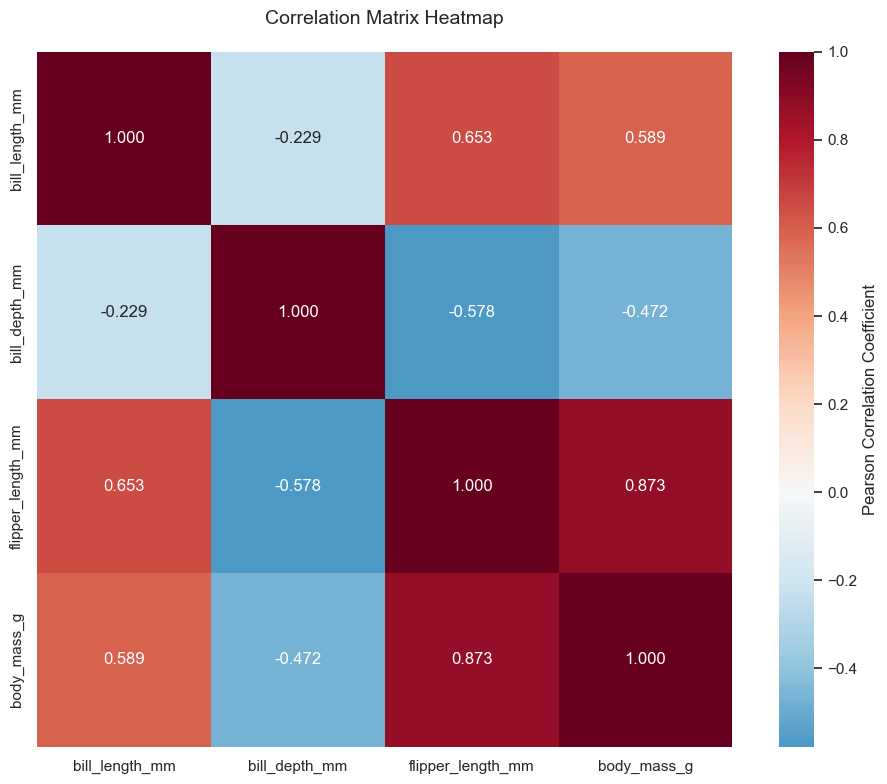

Correlation Summary:
--------------------
Number of correlations: 6
Mean |correlation|: 0.566
Max |correlation|: 0.873
Min |correlation|: 0.229

Correlations by strength:
  Weak: 1 (16.7%)
  Moderate: 4 (66.7%)
  Strong: 1 (16.7%)

Significant correlations: 6 out of 6


In [9]:
def calculate_basic_correlations(data, continuous_vars):
    """
    Calculate and interpret basic Pearson correlations between continuous variables.

    """
    print("\n" + "=" * 70)
    print("BASIC PEARSON CORRELATIONS")
    print("=" * 70)

    # Calculate correlation matrix
    corr_matrix = data[continuous_vars].corr()

    print("Correlation Matrix:")
    print("-" * 20)
    print(corr_matrix.round(3))

    # Extract unique pairs and their correlations
    print(f"\nPairwise Correlations:")
    print("-" * 25)

    correlation_results = []

    for i in range(len(continuous_vars)):
        for j in range(i+1, len(continuous_vars)):
            var1 = continuous_vars[i]
            var2 = continuous_vars[j]

            # FIXED: Calculate correlation with proper alignment
            # Get valid pairs first to ensure alignment
            valid_pairs = data[[var1, var2]].dropna()

            # Calculate correlation and significance test on aligned data
            r, p_value = pearsonr(valid_pairs[var1], valid_pairs[var2])

            # Calculate sample size
            n = len(valid_pairs)

            # Interpret strength
            if abs(r) >= 0.7:
                strength = "Strong"
            elif abs(r) >= 0.3:
                strength = "Moderate"
            else:
                strength = "Weak"

            # Interpret direction
            direction = "Positive" if r > 0 else "Negative"

            # Significance
            significance = "Significant" if p_value < 0.05 else "Not significant"

            correlation_results.append({
                'var1': var1,
                'var2': var2,
                'correlation': r,
                'p_value': p_value,
                'n': n,
                'strength': strength,
                'direction': direction,
                'significance': significance
            })

            print(f"{var1} ↔ {var2}:")
            print(f"  r = {r:>7.3f}, p = {p_value:>7.4f}, n = {n:>3}")
            print(f"  {strength} {direction.lower()} correlation ({significance.lower()})")
            print()

    # Create correlation heatmap
    plt.figure(figsize=(10, 8))

    # Create mask for upper triangle to show only lower triangle
    #mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

    # Create heatmap
    sns.heatmap(corr_matrix,
                #mask=mask,
                annot=True,
                cmap='RdBu_r',
                center=0,
                square=True,
                fmt='.3f',
                cbar_kws={'label': 'Pearson Correlation Coefficient'})

    plt.title('Correlation Matrix Heatmap', fontsize=14, pad=20)
    plt.tight_layout()
    plt.show()

    # Summary statistics
    print(f"Correlation Summary:")
    print("-" * 20)

    correlations_flat = [abs(result['correlation']) for result in correlation_results]
    print(f"Number of correlations: {len(correlations_flat)}")
    print(f"Mean |correlation|: {np.mean(correlations_flat):.3f}")
    print(f"Max |correlation|: {np.max(correlations_flat):.3f}")
    print(f"Min |correlation|: {np.min(correlations_flat):.3f}")

    # Count by strength
    strength_counts = {}
    for result in correlation_results:
        strength = result['strength']
        strength_counts[strength] = strength_counts.get(strength, 0) + 1

    print(f"\nCorrelations by strength:")
    for strength, count in strength_counts.items():
        percentage = (count / len(correlation_results)) * 100
        print(f"  {strength}: {count} ({percentage:.1f}%)")

    # Significant correlations
    significant_corrs = [r for r in correlation_results if r['significance'] == 'Significant']
    print(f"\nSignificant correlations: {len(significant_corrs)} out of {len(correlation_results)}")

    return {
        'correlation_matrix': corr_matrix,
        'pairwise_results': correlation_results,
        'summary_stats': {
            'mean_abs_correlation': np.mean(correlations_flat),
            'max_abs_correlation': np.max(correlations_flat),
            'min_abs_correlation': np.min(correlations_flat),
            'strength_distribution': strength_counts,
            'significant_count': len(significant_corrs)
        }
    }


# Step 3: Calculate basic correlations
correlation_results = calculate_basic_correlations(penguins_clean, continuous_vars)


### Assumption checking for correlation analysis


 EXECUTING ASSUMPTION CHECKING AND SPEARMAN ANALYSIS

 Step 1: Checking correlation assumptions for key variable pairs

COMPREHENSIVE PENGUIN CORRELATION ANALYSIS

 Analyzing flipper_length_mm vs body_mass_g

ASSUMPTION CHECKING: flipper_length_mm vs body_mass_g
Sample size: 333 complete pairs

1. LINEAR RELATIONSHIP
-------------------------
Linear R² = 0.7621
Quadratic R² = 0.7781
R² improvement = 0.0160
Linearity assumption: SATISFIED

2. NORMALITY
---------------
flipper_length_mm: W = 0.9517, p = 0.0000 (Non-normal)
body_mass_g: W = 0.9580, p = 0.0000 (Non-normal)

3. HOMOSCEDASTICITY
--------------------
Breusch-Pagan-like test:
Correlation |residuals| vs fitted: r = -0.1205, p = 0.0278
Homoscedasticity assumption: VIOLATED

4. OUTLIER DETECTION
--------------------
Univariate outliers (|z| > 3):
  flipper_length_mm: 0 (0.0%)
  body_mass_g: 0 (0.0%)
Bivariate outliers (Mahalanobis): 0 (0.0%)
Outlier assumption: SATISFIED


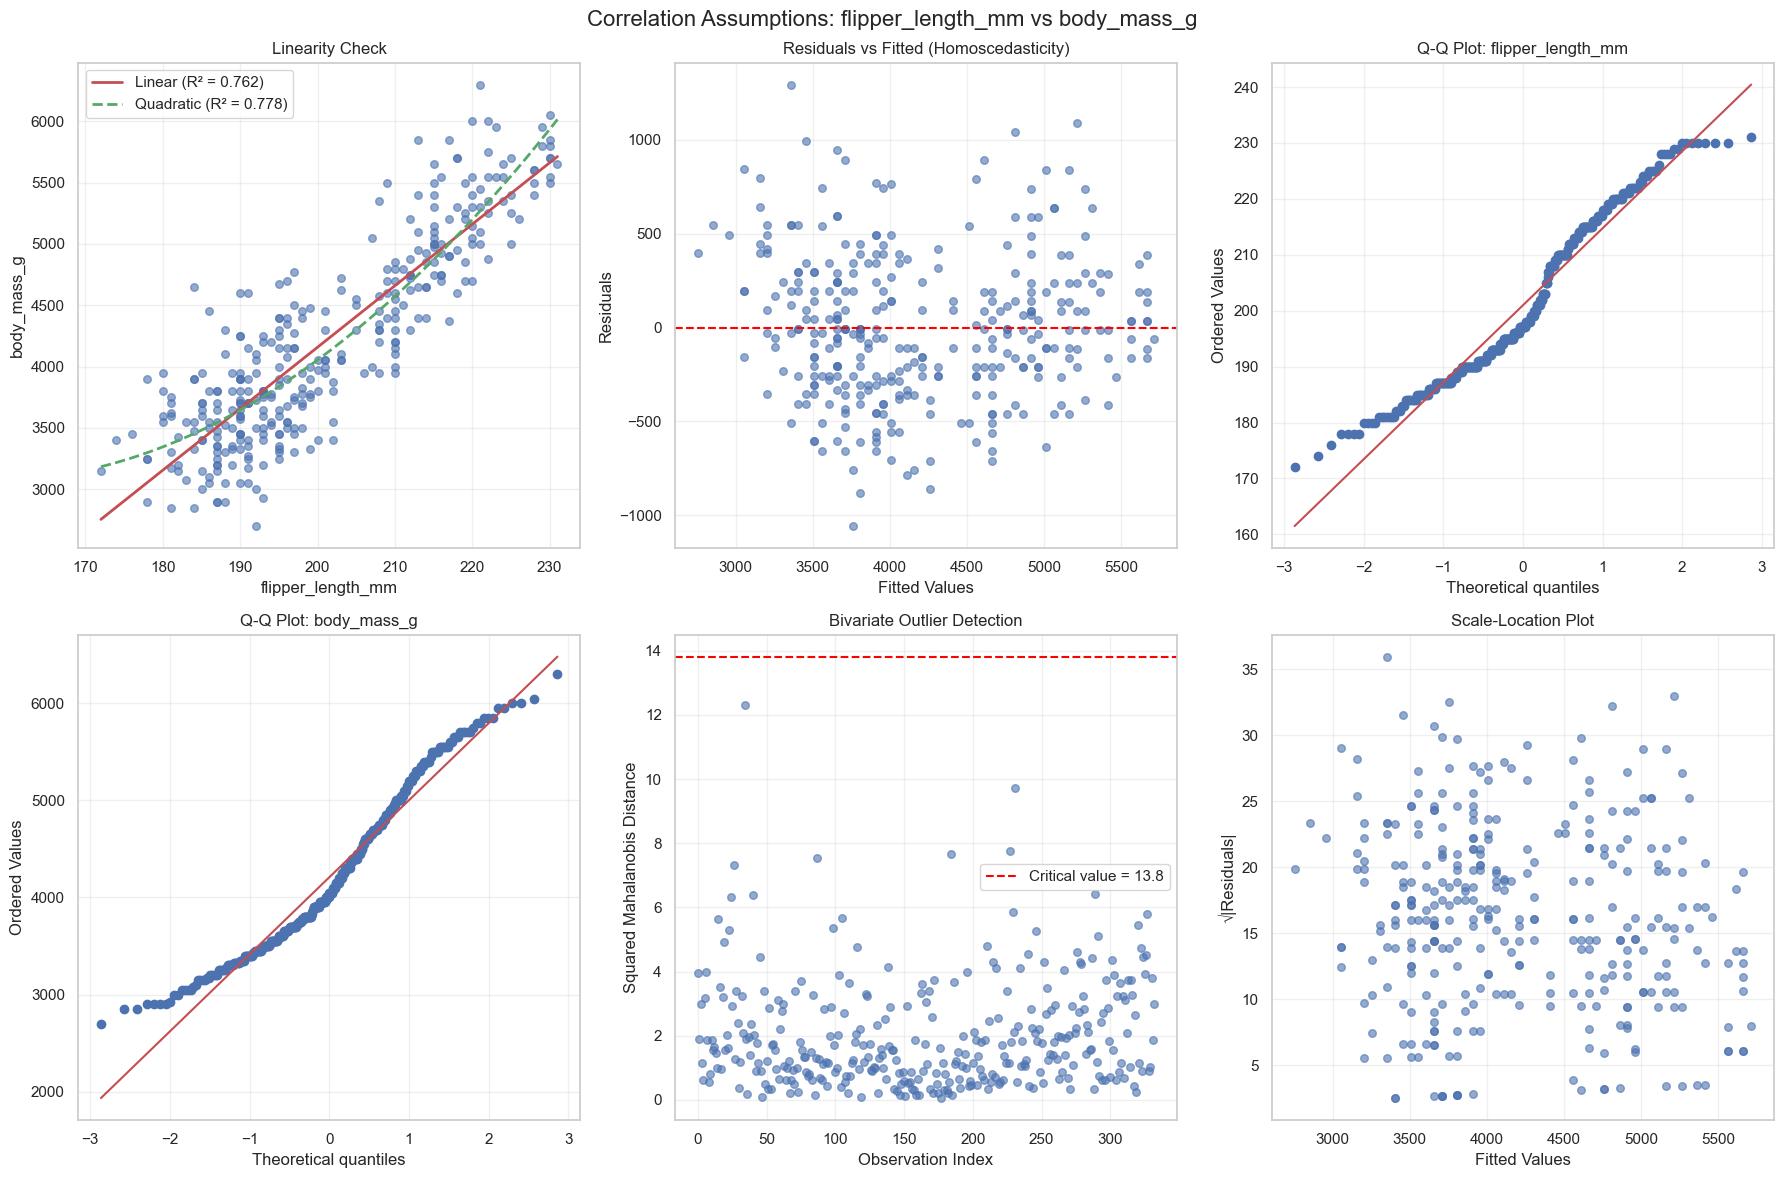


ASSUMPTION CHECK SUMMARY
Assumptions satisfied: 2/5
Recommendation: Consider both Pearson and Spearman correlations

 Analyzing bill_length_mm vs bill_depth_mm

ASSUMPTION CHECKING: bill_length_mm vs bill_depth_mm
Sample size: 333 complete pairs

1. LINEAR RELATIONSHIP
-------------------------
Linear R² = 0.0523
Quadratic R² = 0.1095
R² improvement = 0.0573
Linearity assumption: QUESTIONABLE

2. NORMALITY
---------------
bill_length_mm: W = 0.9743, p = 0.0000 (Non-normal)
bill_depth_mm: W = 0.9733, p = 0.0000 (Non-normal)

3. HOMOSCEDASTICITY
--------------------
Breusch-Pagan-like test:
Correlation |residuals| vs fitted: r = -0.2657, p = 0.0000
Homoscedasticity assumption: VIOLATED

4. OUTLIER DETECTION
--------------------
Univariate outliers (|z| > 3):
  bill_length_mm: 0 (0.0%)
  bill_depth_mm: 0 (0.0%)
Bivariate outliers (Mahalanobis): 0 (0.0%)
Outlier assumption: SATISFIED


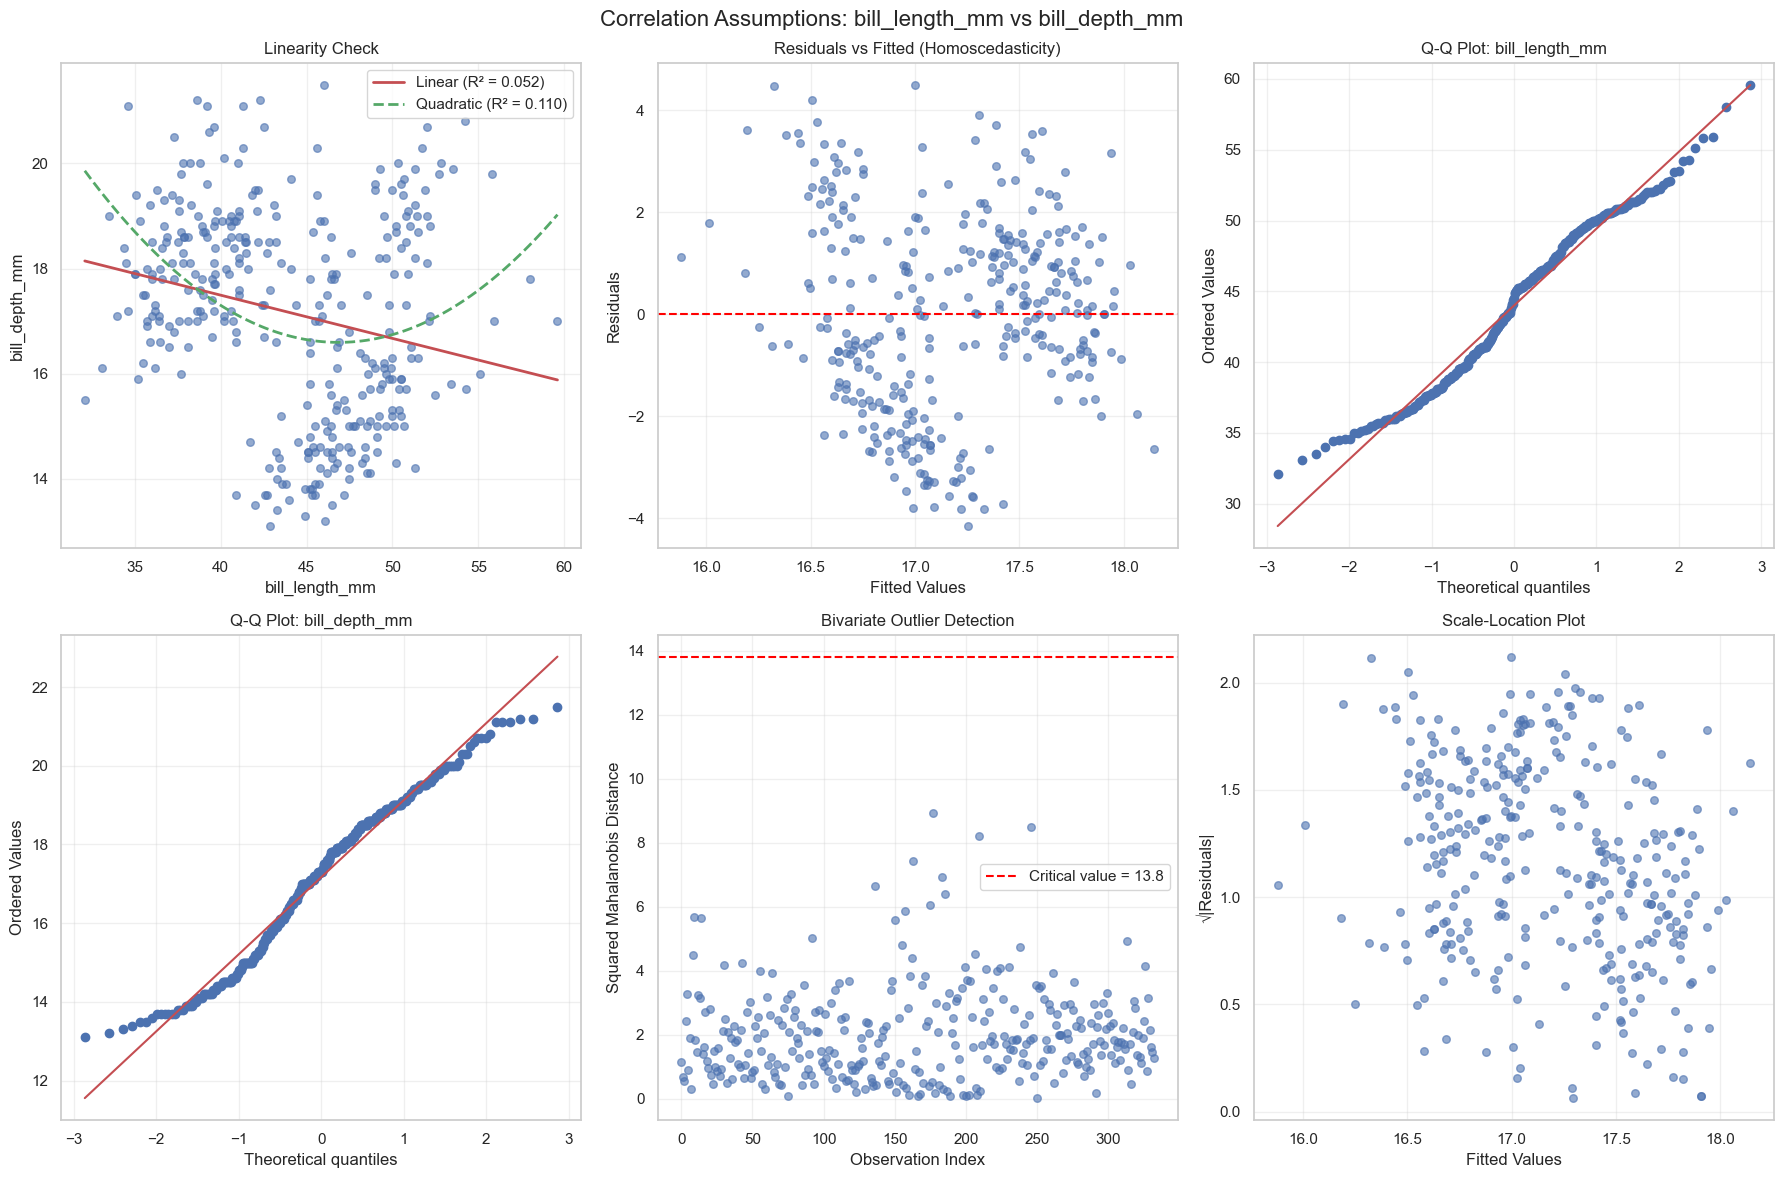


ASSUMPTION CHECK SUMMARY
Assumptions satisfied: 1/5
Recommendation: Spearman correlation recommended

 Analyzing bill_length_mm vs body_mass_g

ASSUMPTION CHECKING: bill_length_mm vs body_mass_g
Sample size: 333 complete pairs

1. LINEAR RELATIONSHIP
-------------------------
Linear R² = 0.3475
Quadratic R² = 0.3604
R² improvement = 0.0130
Linearity assumption: SATISFIED

2. NORMALITY
---------------
bill_length_mm: W = 0.9743, p = 0.0000 (Non-normal)
body_mass_g: W = 0.9580, p = 0.0000 (Non-normal)

3. HOMOSCEDASTICITY
--------------------
Breusch-Pagan-like test:
Correlation |residuals| vs fitted: r = 0.5155, p = 0.0000
Homoscedasticity assumption: VIOLATED

4. OUTLIER DETECTION
--------------------
Univariate outliers (|z| > 3):
  bill_length_mm: 0 (0.0%)
  body_mass_g: 0 (0.0%)
Bivariate outliers (Mahalanobis): 0 (0.0%)
Outlier assumption: SATISFIED


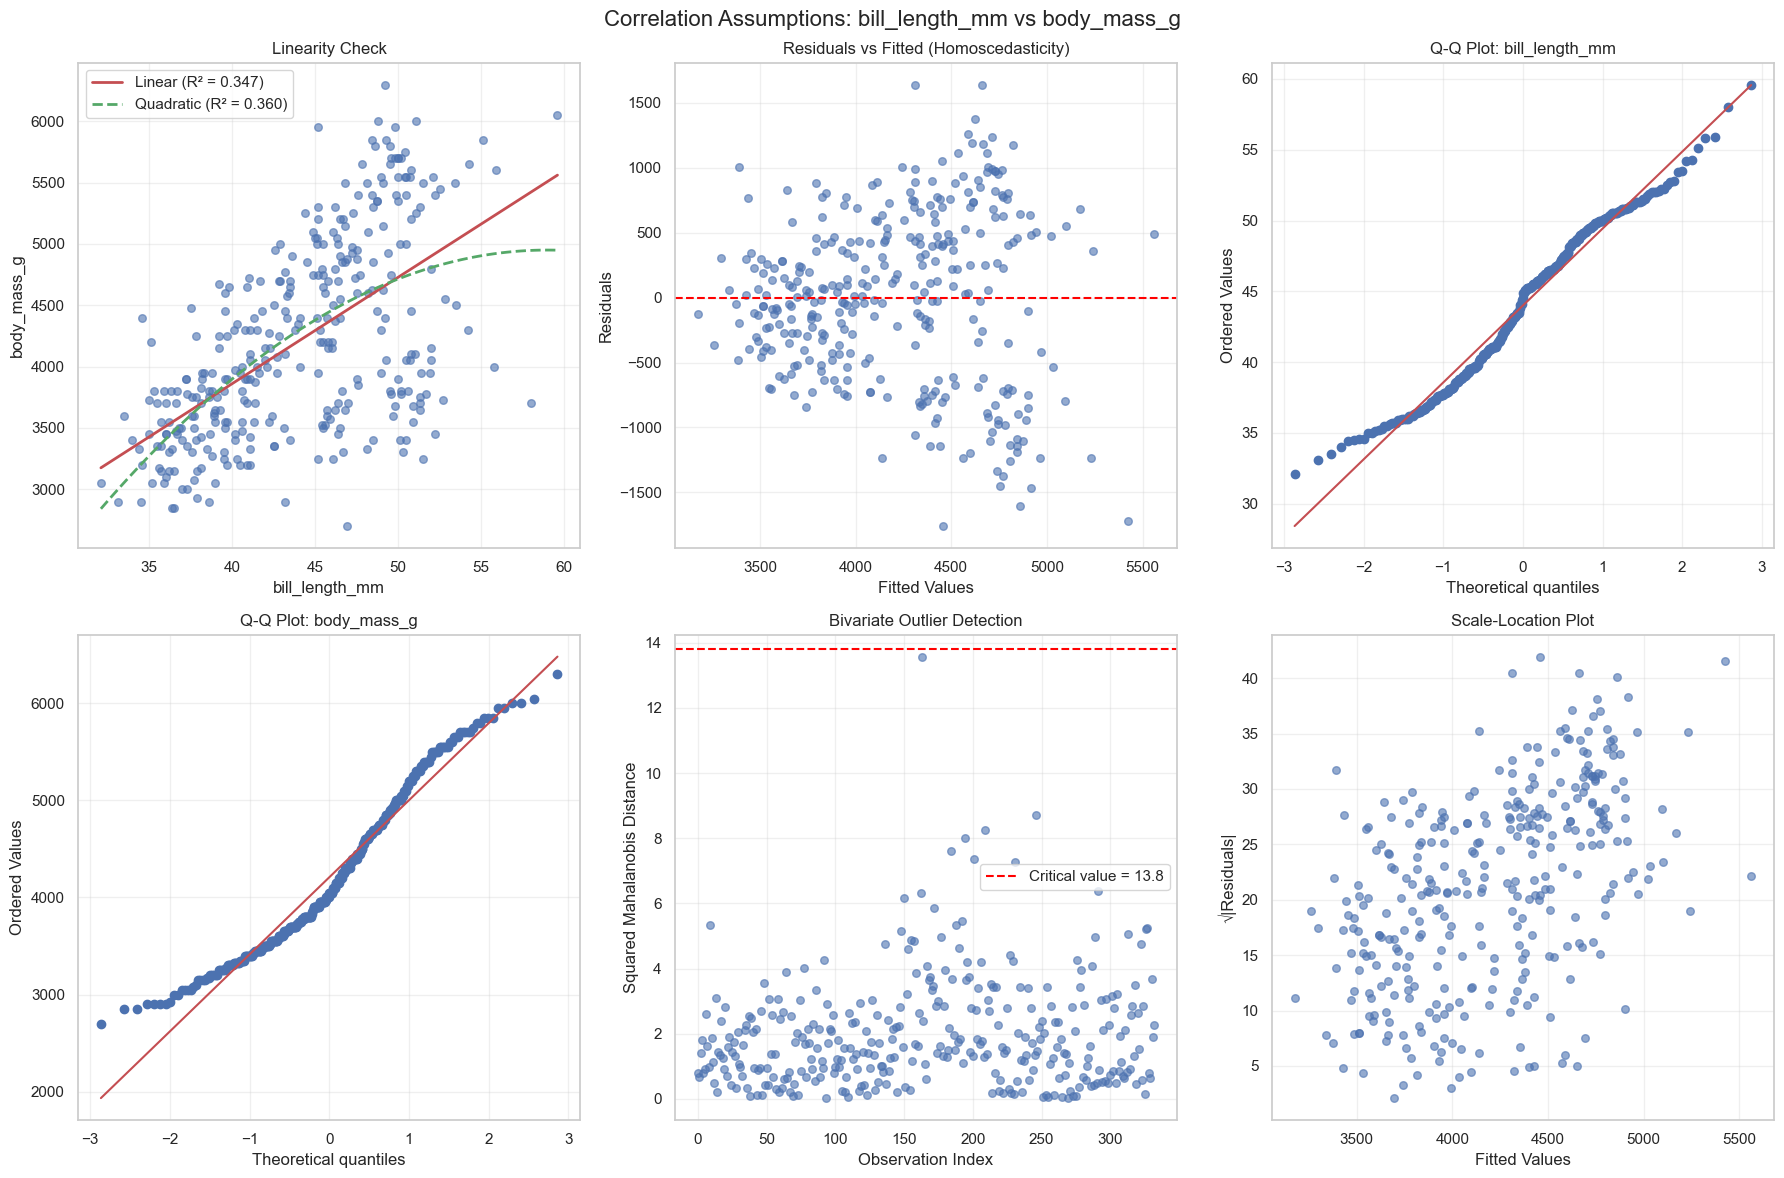


ASSUMPTION CHECK SUMMARY
Assumptions satisfied: 2/5
Recommendation: Consider both Pearson and Spearman correlations

ASSUMPTION CHECK SUMMARY FOR ALL PAIRS

flipper length mm ↔ body mass g:
  Assumptions met: 2/5
  Recommendation: Consider both Pearson and Spearman correlations
  Pearson r = 0.873

bill length mm ↔ bill depth mm:
  Assumptions met: 1/5
  Recommendation: Spearman correlation recommended
  Pearson r = -0.229

bill length mm ↔ body mass g:
  Assumptions met: 2/5
  Recommendation: Consider both Pearson and Spearman correlations
  Pearson r = 0.589

 Step 2: Spearman correlation analysis

SPEARMAN'S RANK CORRELATION ANALYSIS
Spearman's rank correlation (ρ) measures monotonic relationships
It's robust to outliers and doesn't assume normality or linearity

Spearman Correlation Matrix:
------------------------------
                   bill_length_mm  bill_depth_mm  flipper_length_mm  \
bill_length_mm              1.000         -0.214              0.670   
bill_depth_mm       

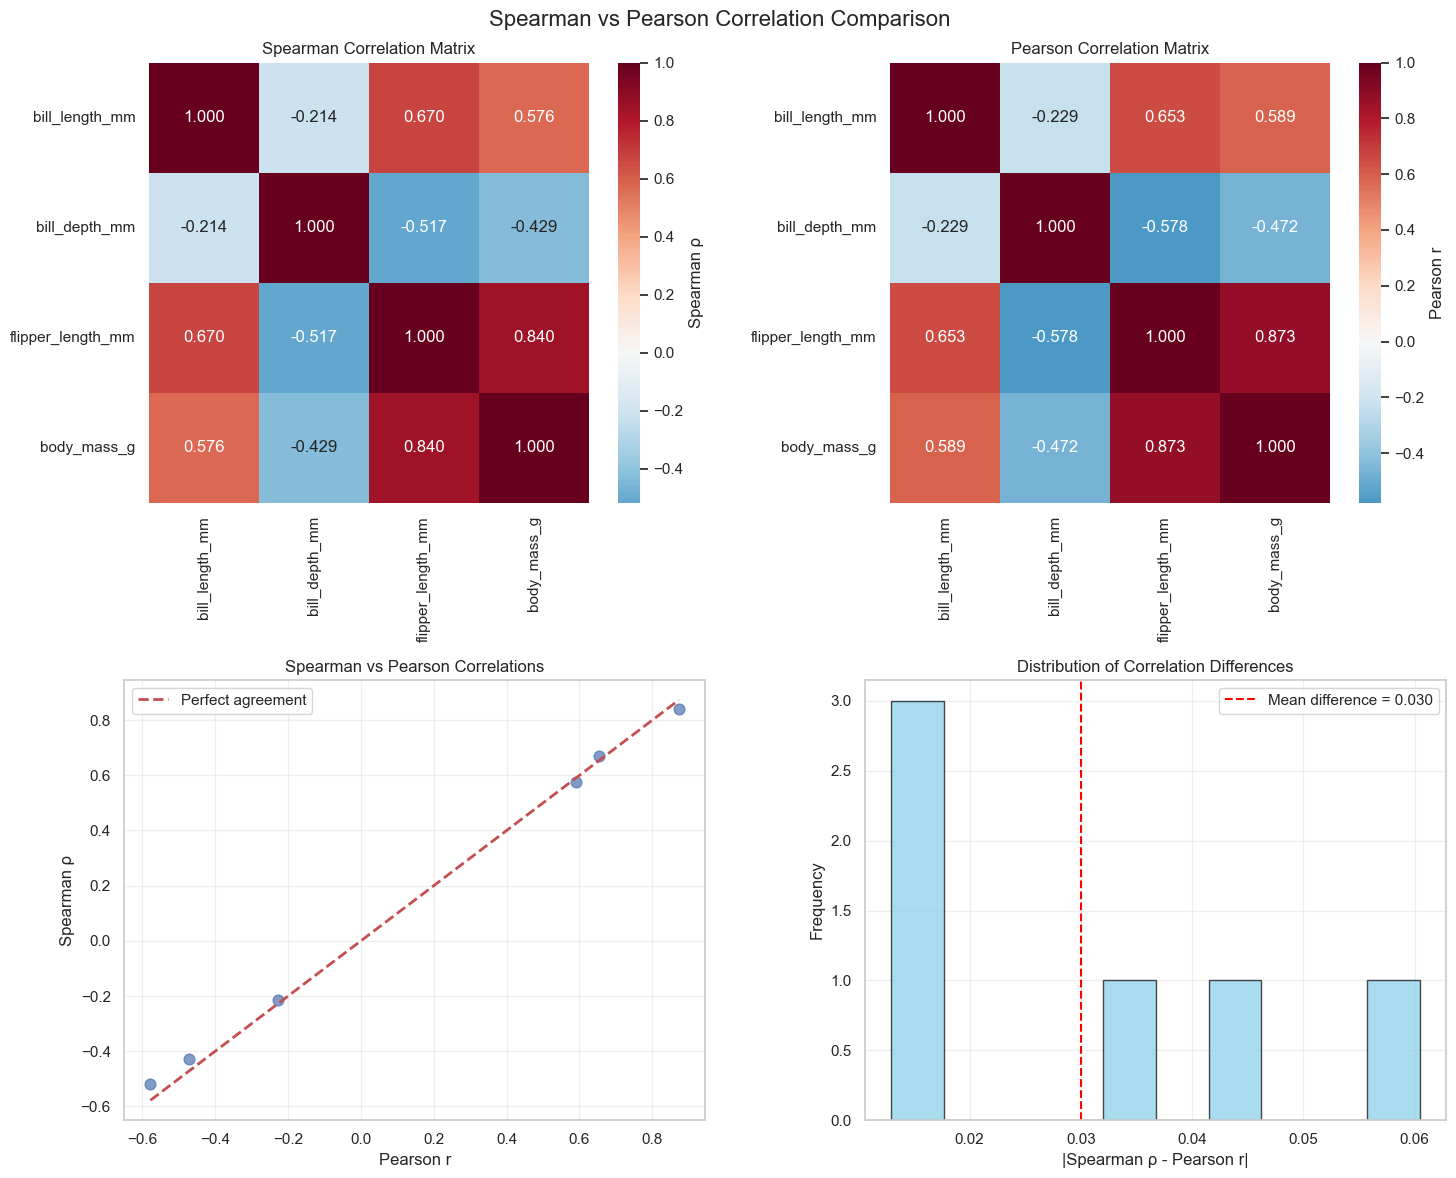

Comparison Summary:
--------------------
Mean absolute difference: 0.030
Maximum difference: 0.060
Number of pairs with |diff| > 0.1: 0
Number of pairs with |diff| > 0.2: 0


In [10]:
def check_correlation_assumptions(data, var1, var2, create_plots=True):
    """
    Assumption checking for Pearson correlation between two variables.
    """
    print(f"\n" + "=" * 60)
    print(f"ASSUMPTION CHECKING: {var1} vs {var2}")
    print("=" * 60)

    # Get clean data for the pair
    clean_data = data[[var1, var2]].dropna()
    x = clean_data[var1]
    y = clean_data[var2]
    n = len(clean_data)

    print(f"Sample size: {n} complete pairs")

    # 1. Linear relationship check
    print(f"\n1. LINEAR RELATIONSHIP")
    print("-" * 25)

    # Calculate Pearson correlation
    r_pearson, p_pearson = pearsonr(x, y)

    # Fit polynomial models to test for non-linearity
    #Note: Remember that R-squared indicates how well the model fits the data
    # Linear model (degree 1)
    linear_coef = np.polyfit(x, y, 1)
    linear_pred = np.polyval(linear_coef, x)
    linear_r2 = 1 - (np.sum((y - linear_pred) ** 2) / np.sum((y - np.mean(y)) ** 2))

    # Quadratic model (degree 2)
    quad_coef = np.polyfit(x, y, 2)
    quad_pred = np.polyval(quad_coef, x)
    quad_r2 = 1 - (np.sum((y - quad_pred) ** 2) / np.sum((y - np.mean(y)) ** 2))

    # Test for non-linearity
    r2_improvement = quad_r2 - linear_r2
    linearity_ok = r2_improvement < 0.05  # Arbitrary threshold

    print(f"Linear R² = {linear_r2:.4f}")
    print(f"Quadratic R² = {quad_r2:.4f}")
    print(f"R² improvement = {r2_improvement:.4f}")
    print(f"Linearity assumption: {'SATISFIED' if linearity_ok else 'QUESTIONABLE'}")

    # 2. Normality check
    print(f"\n2. NORMALITY")
    print("-" * 15)

    # Shapiro-Wilk tests (use sample if too large)
    x_sample = x.sample(min(5000, len(x)), random_state=42) if len(x) > 5000 else x
    y_sample = y.sample(min(5000, len(y)), random_state=42) if len(y) > 5000 else y

    shapiro_x = stats.shapiro(x_sample)
    shapiro_y = stats.shapiro(y_sample)

    normality_x = shapiro_x.pvalue > 0.05
    normality_y = shapiro_y.pvalue > 0.05

    print(f"{var1}: W = {shapiro_x.statistic:.4f}, p = {shapiro_x.pvalue:.4f} ({'Normal' if normality_x else 'Non-normal'})")
    print(f"{var2}: W = {shapiro_y.statistic:.4f}, p = {shapiro_y.pvalue:.4f} ({'Normal' if normality_y else 'Non-normal'})")

    # 3. Homoscedasticity check
    print(f"\n3. HOMOSCEDASTICITY")
    print("-" * 20)

    # Calculate residuals from linear regression
    residuals = y - linear_pred

    # Breusch-Pagan test for heteroscedasticity
    # Simple version: correlation between |residuals| and fitted values
    abs_residuals = np.abs(residuals)
    fitted_values = linear_pred

    hetero_corr, hetero_p = pearsonr(fitted_values, abs_residuals)
    homoscedasticity_ok = hetero_p > 0.05

    print(f"Breusch-Pagan-like test:")
    print(f"Correlation |residuals| vs fitted: r = {hetero_corr:.4f}, p = {hetero_p:.4f}")
    print(f"Homoscedasticity assumption: {'SATISFIED' if homoscedasticity_ok else 'VIOLATED'}")

    # 4. Outlier detection
    print(f"\n4. OUTLIER DETECTION")
    print("-" * 20)

    # Z-score method for univariate outliers
    #Note: Remember that Z-score indicates how many standard deviations a data point is from the mean of a distribution
    z_scores_x = np.abs(stats.zscore(x))
    z_scores_y = np.abs(stats.zscore(y))

    outliers_x = np.sum(z_scores_x > 3)
    outliers_y = np.sum(z_scores_y > 3)

    # Bivariate outliers using Mahalanobis distance
    data_array = np.column_stack([x, y])    # Combine x and y into a 2D array
    mean_vec = np.mean(data_array, axis=0)   # Calculate mean of x and mean of y
    cov_matrix = np.cov(data_array.T)    # Calculate covariance matrix

    try:
        inv_cov = np.linalg.inv(cov_matrix)   # Invert the covariance matrix
        mahal_dist = []
        for i in range(len(data_array)):
            diff = data_array[i] - mean_vec   # How far this point is from the center
            mahal_dist.append(np.sqrt(diff.T @ inv_cov @ diff))  # Mahalanobis distance formula

        mahal_dist = np.array(mahal_dist)
        # Chi-square critical value for 2 variables at 99.9% confidence
        chi2_critical = stats.chi2.ppf(0.999, df=2)    # Get chi-square threshold for 99.9% confidence
        bivariate_outliers = np.sum(mahal_dist**2 > chi2_critical)  # Count outliers

    except np.linalg.LinAlgError:
        bivariate_outliers = 0
        mahal_dist = np.zeros(len(data_array))

    total_outliers = max(outliers_x, outliers_y, bivariate_outliers)
    outliers_ok = total_outliers < (0.05 * n)  # Less than 5% outliers

    print(f"Univariate outliers (|z| > 3):")
    print(f"  {var1}: {outliers_x} ({outliers_x/n*100:.1f}%)")
    print(f"  {var2}: {outliers_y} ({outliers_y/n*100:.1f}%)")
    print(f"Bivariate outliers (Mahalanobis): {bivariate_outliers} ({bivariate_outliers/n*100:.1f}%)")
    print(f"Outlier assumption: {'SATISFIED' if outliers_ok else 'ATTENTION NEEDED'}")

    # Create diagnostic plots if requested
    if create_plots:
        fig, axes = plt.subplots(2, 3, figsize=(18, 12))
        fig.suptitle(f'Correlation Assumptions: {var1} vs {var2}', fontsize=16)

        # Plot 1: Scatter plot with linear and quadratic fits
        axes[0, 0].scatter(x, y, alpha=0.6, s=30)

        # Linear fit
        x_line = np.linspace(x.min(), x.max(), 100)
        y_linear = np.polyval(linear_coef, x_line)
        y_quad = np.polyval(quad_coef, x_line)

        axes[0, 0].plot(x_line, y_linear, 'r-', linewidth=2, label=f'Linear (R² = {linear_r2:.3f})')
        axes[0, 0].plot(x_line, y_quad, 'g--', linewidth=2, label=f'Quadratic (R² = {quad_r2:.3f})')

        axes[0, 0].set_xlabel(var1)
        axes[0, 0].set_ylabel(var2)
        axes[0, 0].set_title('Linearity Check')
        axes[0, 0].legend()
        axes[0, 0].grid(True, alpha=0.3)

        # Plot 2: Residuals vs Fitted (homoscedasticity)
        axes[0, 1].scatter(fitted_values, residuals, alpha=0.6, s=30)
        axes[0, 1].axhline(y=0, color='red', linestyle='--')
        axes[0, 1].set_xlabel('Fitted Values')
        axes[0, 1].set_ylabel('Residuals')
        axes[0, 1].set_title('Residuals vs Fitted (Homoscedasticity)')
        axes[0, 1].grid(True, alpha=0.3)

        # Plot 3: Q-Q plot for X variable
        stats.probplot(x, dist="norm", plot=axes[0, 2])
        axes[0, 2].set_title(f'Q-Q Plot: {var1}')
        axes[0, 2].grid(True, alpha=0.3)

        # Plot 4: Q-Q plot for Y variable
        stats.probplot(y, dist="norm", plot=axes[1, 0])
        axes[1, 0].set_title(f'Q-Q Plot: {var2}')
        axes[1, 0].grid(True, alpha=0.3)

        # Plot 5: Outlier detection (Mahalanobis distance)
        if len(mahal_dist) > 0:
            axes[1, 1].scatter(range(len(mahal_dist)), mahal_dist**2, alpha=0.6, s=30)
            axes[1, 1].axhline(y=chi2_critical, color='red', linestyle='--',
                              label=f'Critical value = {chi2_critical:.1f}')
            axes[1, 1].set_xlabel('Observation Index')
            axes[1, 1].set_ylabel('Squared Mahalanobis Distance')
            axes[1, 1].set_title('Bivariate Outlier Detection')
            axes[1, 1].legend()
        axes[1, 1].grid(True, alpha=0.3)

        # Plot 6: Scale-Location plot
        sqrt_abs_residuals = np.sqrt(np.abs(residuals))
        axes[1, 2].scatter(fitted_values, sqrt_abs_residuals, alpha=0.6, s=30)
        axes[1, 2].set_xlabel('Fitted Values')
        axes[1, 2].set_ylabel('√|Residuals|')
        axes[1, 2].set_title('Scale-Location Plot')
        axes[1, 2].grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()

    # Summary
    assumptions_met = sum([linearity_ok, normality_x, normality_y, homoscedasticity_ok, outliers_ok])
    total_assumptions = 5

    print(f"\n" + "=" * 50)
    print("ASSUMPTION CHECK SUMMARY")
    print("=" * 50)
    print(f"Assumptions satisfied: {assumptions_met}/{total_assumptions}")

    if assumptions_met >= 4:
        recommendation = "Pearson correlation is appropriate"
    elif assumptions_met >= 2:
        recommendation = "Consider both Pearson and Spearman correlations"
    else:
        recommendation = "Spearman correlation recommended"

    print(f"Recommendation: {recommendation}")

    return {
        'linearity': linearity_ok,
        'normality_x': normality_x,
        'normality_y': normality_y,
        'homoscedasticity': homoscedasticity_ok,
        'outliers_ok': outliers_ok,
        'assumptions_met': assumptions_met,
        'recommendation': recommendation,
        'pearson_r': r_pearson,
        'sample_size': n,
        'outlier_counts': {
            'univariate_x': outliers_x,
            'univariate_y': outliers_y,
            'bivariate': bivariate_outliers
        }
    }


def perform_spearman_correlation(data, continuous_vars):
    """
    Perform Spearman's rank correlation analysis as a non-parametric alternative.
    """
    print(f"\n" + "=" * 70)
    print("SPEARMAN'S RANK CORRELATION ANALYSIS")
    print("=" * 70)

    print("Spearman's rank correlation (ρ) measures monotonic relationships")
    print("It's robust to outliers and doesn't assume normality or linearity")
    print()

    # Calculate Spearman correlation matrix - using pandas .corr function - all pairs results simultaneously
    # Note: The .corr(method='spearman' method automatically converts data to ranks
    spearman_matrix = data[continuous_vars].corr(method='spearman')

    print("Spearman Correlation Matrix:")
    print("-" * 30)
    print(spearman_matrix.round(3))

    # Compare with Pearson correlations
    pearson_matrix = data[continuous_vars].corr(method='pearson')

# Just so we can print p-values, let us do this individually, for each pair of variables at a time
# using the scipy.stats functions, which returns the p-values
    print(f"\nSpearman vs Pearson Correlations:")
    print("-" * 35)

    spearman_results = []

    for i in range(len(continuous_vars)):
        for j in range(i+1, len(continuous_vars)):
            var1 = continuous_vars[i]
            var2 = continuous_vars[j]

            # Get aligned data first, then calculate correlations
            clean_data = data[[var1, var2]].dropna()
            x = clean_data[var1]
            y = clean_data[var2]

            # Spearman correlation (using function from scipy.stats)
            rho, p_spearman = spearmanr(x, y)

            # Pearson correlation for comparison (using function from scipy.stats)
            r_pearson, p_pearson = pearsonr(x, y)

            # Calculate difference
            diff = abs(rho - r_pearson)

            spearman_results.append({
                'var1': var1,
                'var2': var2,
                'spearman_rho': rho,
                'spearman_p': p_spearman,
                'pearson_r': r_pearson,
                'pearson_p': p_pearson,
                'difference': diff,
                'sample_size': len(clean_data)
            })

            # Interpret difference
            if diff < 0.1:
                agreement = "High agreement"
            elif diff < 0.2:
                agreement = "Moderate agreement"
            else:
                agreement = "Poor agreement"

            print(f"{var1} ↔ {var2}:")
            print(f"  Spearman ρ = {rho:>7.3f} (p = {p_spearman:>6.4f})")
            print(f"  Pearson  r = {r_pearson:>7.3f} (p = {p_pearson:>6.4f})")
            print(f"  Difference = {diff:>7.3f} ({agreement})")
            print()

    # Create comparison visualization
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    fig.suptitle('Spearman vs Pearson Correlation Comparison', fontsize=16)

    # Plot 1: Spearman correlation heatmap
    #mask = np.triu(np.ones_like(spearman_matrix, dtype=bool))
    sns.heatmap(spearman_matrix,
                #mask=mask,
                annot=True, cmap='RdBu_r', center=0,
                square=True, fmt='.3f', ax=axes[0, 0],
                cbar_kws={'label': 'Spearman ρ'})
    axes[0, 0].set_title('Spearman Correlation Matrix')

    # Plot 2: Pearson correlation heatmap
    sns.heatmap(pearson_matrix,
                #mask=mask,
                annot=True, cmap='RdBu_r', center=0,
                square=True, fmt='.3f', ax=axes[0, 1],
                cbar_kws={'label': 'Pearson r'})
    axes[0, 1].set_title('Pearson Correlation Matrix')

    # Plot 3: Spearman vs Pearson scatter plot
    spearman_values = []
    pearson_values = []

    for result in spearman_results:
        spearman_values.append(result['spearman_rho'])
        pearson_values.append(result['pearson_r'])

    axes[1, 0].scatter(pearson_values, spearman_values, alpha=0.7, s=60)

    # Add diagonal line (perfect agreement)
    min_val = min(min(spearman_values), min(pearson_values))
    max_val = max(max(spearman_values), max(pearson_values))
    axes[1, 0].plot([min_val, max_val], [min_val, max_val], 'r--',
                   linewidth=2, label='Perfect agreement')

    axes[1, 0].set_xlabel('Pearson r')
    axes[1, 0].set_ylabel('Spearman ρ')
    axes[1, 0].set_title('Spearman vs Pearson Correlations')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)

    # Plot 4: Difference magnitude histogram
    differences = [result['difference'] for result in spearman_results]
    axes[1, 1].hist(differences, bins=10, alpha=0.7, color='skyblue', edgecolor='black')
    axes[1, 1].set_xlabel('|Spearman ρ - Pearson r|')
    axes[1, 1].set_ylabel('Frequency')
    axes[1, 1].set_title('Distribution of Correlation Differences')
    axes[1, 1].grid(True, alpha=0.3)

    # Add statistics
    mean_diff = np.mean(differences)
    max_diff = np.max(differences)
    axes[1, 1].axvline(mean_diff, color='red', linestyle='--',
                      label=f'Mean difference = {mean_diff:.3f}')
    axes[1, 1].legend()

    plt.tight_layout()
    plt.show()

    # Summary statistics
    print(f"Comparison Summary:")
    print("-" * 20)
    print(f"Mean absolute difference: {mean_diff:.3f}")
    print(f"Maximum difference: {max_diff:.3f}")
    print(f"Number of pairs with |diff| > 0.1: {sum(1 for d in differences if d > 0.1)}")
    print(f"Number of pairs with |diff| > 0.2: {sum(1 for d in differences if d > 0.2)}")

    return {
        'spearman_matrix': spearman_matrix,
        'pairwise_results': spearman_results,
        'comparison_stats': {
            'mean_difference': mean_diff,
            'max_difference': max_diff,
            'differences': differences
        }
    }


def analyze_penguin_correlations_comprehensive(data, continuous_vars):
    """
    Comprehensive correlation analysis of penguin data with both methods.
    """
    print(f"\n" + "=" * 70)
    print("COMPREHENSIVE PENGUIN CORRELATION ANALYSIS")
    print("=" * 70)

    # Check assumptions for key variable pairs
    key_pairs = [
        ('flipper_length_mm', 'body_mass_g'),
        ('bill_length_mm', 'bill_depth_mm'),
        ('bill_length_mm', 'body_mass_g')
    ]

    assumption_results = {}

    for var1, var2 in key_pairs:
        print(f"\n Analyzing {var1} vs {var2}")
        assumption_results[f"{var1}_{var2}"] = check_correlation_assumptions(
            data, var1, var2, create_plots=True
        )

    # Summary of assumption checks
    print(f"\n" + "=" * 50)
    print("ASSUMPTION CHECK SUMMARY FOR ALL PAIRS")
    print("=" * 50)

    for pair_name, results in assumption_results.items():
        # FIXED: More robust string splitting
        parts = pair_name.split('_')
        # Reconstruct variable names properly
        if len(parts) >= 4:  # e.g., "bill_length_mm_body_mass_g"
            var1 = '_'.join(parts[:-3])  # Everything except last 3 parts
            var2 = '_'.join(parts[-3:])  # Last 3 parts
        else:
            var1, var2 = pair_name.split('_', 1)

        var1_clean = var1.replace('_', ' ')
        var2_clean = var2.replace('_', ' ')

        print(f"\n{var1_clean} ↔ {var2_clean}:")
        print(f"  Assumptions met: {results['assumptions_met']}/5")
        print(f"  Recommendation: {results['recommendation']}")
        print(f"  Pearson r = {results['pearson_r']:.3f}")

    return assumption_results


# Execute the analysis
print("\n EXECUTING ASSUMPTION CHECKING AND SPEARMAN ANALYSIS")
print("=" * 60)

# Step 1: Comprehensive assumption checking
print("\n Step 1: Checking correlation assumptions for key variable pairs")
penguin_assumptions = analyze_penguin_correlations_comprehensive(penguins_clean, continuous_vars)

# Step 2: Spearman correlation analysis
print("\n Step 2: Spearman correlation analysis")
spearman_results = perform_spearman_correlation(penguins_clean, continuous_vars)
     

### Partial Correlation 

### 1. Core Concept & Purpose
- The Core Question
    * Partial correlation answers the question: "What would the correlation between variable $X$ and variable $Y$ be if we held the confounding variable $Z$ constant?"
- Confounding Variable (Confounder)
    * A third variable ($Z$) that influences both primary variables ($X$ and $Y$), which can create a misleading or artificial correlation between them.
- Penguin Analogy
    * If bill length ($X$) and body mass ($Y$) show a strong positive correlation, it might simply be because larger penguin species ($Z$) naturally have both longer bills and higher body mass.
    * Partial correlation removes the effect of species to determine if the relationship exists independently of species size.
- partial correlation - it helps us to understand the relationship between two variable after removing the influence of a third variable.


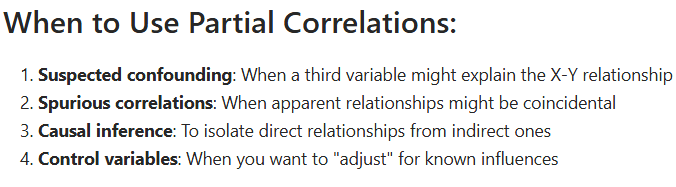



### 2. Mathematical & Algorithmic Methods
- Method 1: The Regression Residuals Approach (Most Intuitive)
    1. Fit Linear Regressions: Predict variable $X$ as a function of the control variable $Z$, and predict variable $Y$ as a function of $Z$.
    2. Extract Residuals: Subtract the predicted values from the actual values to isolate the leftover variation (residuals) not explained by $Z$:
       $$\text{Residual}_X = X - X_{\text{predicted}}$$
       $$\text{Residual}_Y = Y - Y_{\text{predicted}}$$
    3. Compute Pearson Correlation: Calculate the standard Pearson correlation ($R$) between $\text{Residual}_X$ and $\text{Residual}_Y$.
    4. Intuition: By stripping out everything that $Z$ explains about both $X$ and $Y$, the remaining correlation belongs purely to the direct relationship between $X$ and $Y$.

- Method 2: The Direct Formula (Single Confounder)
    * Equation: For two variables $X$ and $Y$ controlled for a single variable $Z$:
      $$r_{XY\cdot Z} = \frac{r_{XY} - r_{XZ} \cdot r_{YZ}}{\sqrt{(1 - r_{XZ}^2)(1 - r_{YZ}^2)}}$$
    * Components: Uses the pairwise simple Pearson correlations ($r_{XY}$, $r_{XZ}$, and $r_{YZ}$).
    * Limitation: Primarily suitable when controlling for a single confounder variable at a time.

### 3. Synthetic Data Simulation: 3 Classic Scenarios
- Scenario 1: Truly Confounded (Spurious Relationship)
    * Setup: $X$ and $Y$ are generated purely as functions of $Z$ with no direct link between $X$ and $Y$.
    * Simple Correlation ($r_{XY}$): $\approx 0.498$ (appears to have a moderate-to-strong correlation).
    * Partial Correlation ($r_{XY\cdot Z}$): $\approx 0.02$ (drops essentially to zero).
    * Conclusion: $X$ and $Y$ are only related through $Z$.
- Scenario 2: Both Direct & Indirect Relationships
    * Setup: $X$ is a function of $Z$, and $Y$ is a function of both $Z$ and $X$.
    * Simple Correlation ($r_{XY}$): $\approx 0.769$.
    * Partial Correlation ($r_{XY\cdot Z}$): $\approx 0.515$.
    * Conclusion: $X$ and $Y$ maintain a true direct relationship even after accounting for the indirect influence of $Z$.
- Scenario 3: Suppressor Variable
    * Setup: $Y$ depends positively on $X$ but negatively on $Z$, where $Z$ suppresses the true $X$-$Y$ relationship.
    * Outcome: Controlling for $Z$ unmasks the true underlying relationship between $X$ and $Y$.

### 4. Practical Handling of Categorical Confounders in Python
- Handling Dummy Variables & Multicollinearity
    * Categorical Variables: When the confounder is categorical (e.g., Palmer Penguin species: Adelie, Chinstrap, Gentoo), it must be converted to numerical dummy variables using one-hot encoding (`pandas.get_dummies`).
    * The `drop_first=True` Rule: For $N$ categories (e.g., 3 species), create only $N-1$ dummy variables (2 dummy variables).
    * Avoiding the Dummy Variable Trap: Including all 3 dummy variables causes them to sum perfectly to 1, creating multicollinearity which breaks the linear regression matrix calculations.
    * Reference Group: The dropped category (e.g., Adelie) becomes the implicit reference baseline against which the remaining dummy variables (Chinstrap, Gentoo) are measured.

### 5. Palmer Penguins Dataset Results & Interpretation

| Variable 1 ($X$) | Variable 2 ($Y$) | Controlled Confounder ($Z$) | Simple $R$ | Partial $R$ | Difference ($\Delta R$) | Interpretation |
| :--- | :--- | :--- | :---: | :---: | :---: | :--- |
| **Bill Length** | Body Mass | Species (Chinstrap, Gentoo) | $0.5895$ | $0.5823$ | $0.0072$ | Minimal Effect: Relationship is genuine and exists largely within species. |
| **Flipper Length** | Body Mass | Species (Chinstrap, Gentoo) | $0.8700$ | $0.5880$ | $0.2850$ | Major Confounder: Species accounts for a significant portion of the raw correlation. |
| **Bill Length** | Bill Depth | Species (Chinstrap, Gentoo) | Clustered | Adjusted | High | Major Confounder: Data forms distinct species clusters. |

- Rule of Thumb for Interpretation
    * $\Delta R > 0.20$: Indicates a major confounding effect where the third variable significantly distorts the unadjusted relationship.
    * $\Delta R < 0.10$: Indicates that the correlation is largely genuine within groups and not merely an artifact of the confounder.

### 6. Key Biological Takeaways
- Genuine Biological Scaling
    * The relationship between bill length and body mass remains strong ($R \approx 0.58$) even after controlling for species differences.
- Scientific Validity
    * This proves genuine biological scaling (larger individual penguins naturally have proportionally longer bills and higher body mass) rather than an artificial grouping artifact.


 Step 1: Demonstrating partial correlation concepts

PARTIAL CORRELATION CONCEPTS: SIMULATED EXAMPLES

Scenario 1: True Confounding
------------------------------
Scenario 2: Partial Relationship
--------------------------------
Scenario 3: Suppressor Variable
--------------------------------
True Confounding:
  Simple correlation: 0.498
  Partial correlation: -0.020
  Difference: 0.518
  Interpretation: X and Y related only through Z

Partial Relationship:
  Simple correlation: 0.769
  Partial correlation: 0.515
  Difference: 0.254
  Interpretation: X and Y have both direct and indirect relationships

Suppressor Variable:
  Simple correlation: 0.588
  Partial correlation: 0.805
  Difference: -0.217
  Interpretation: Z suppresses the true X-Y relationship



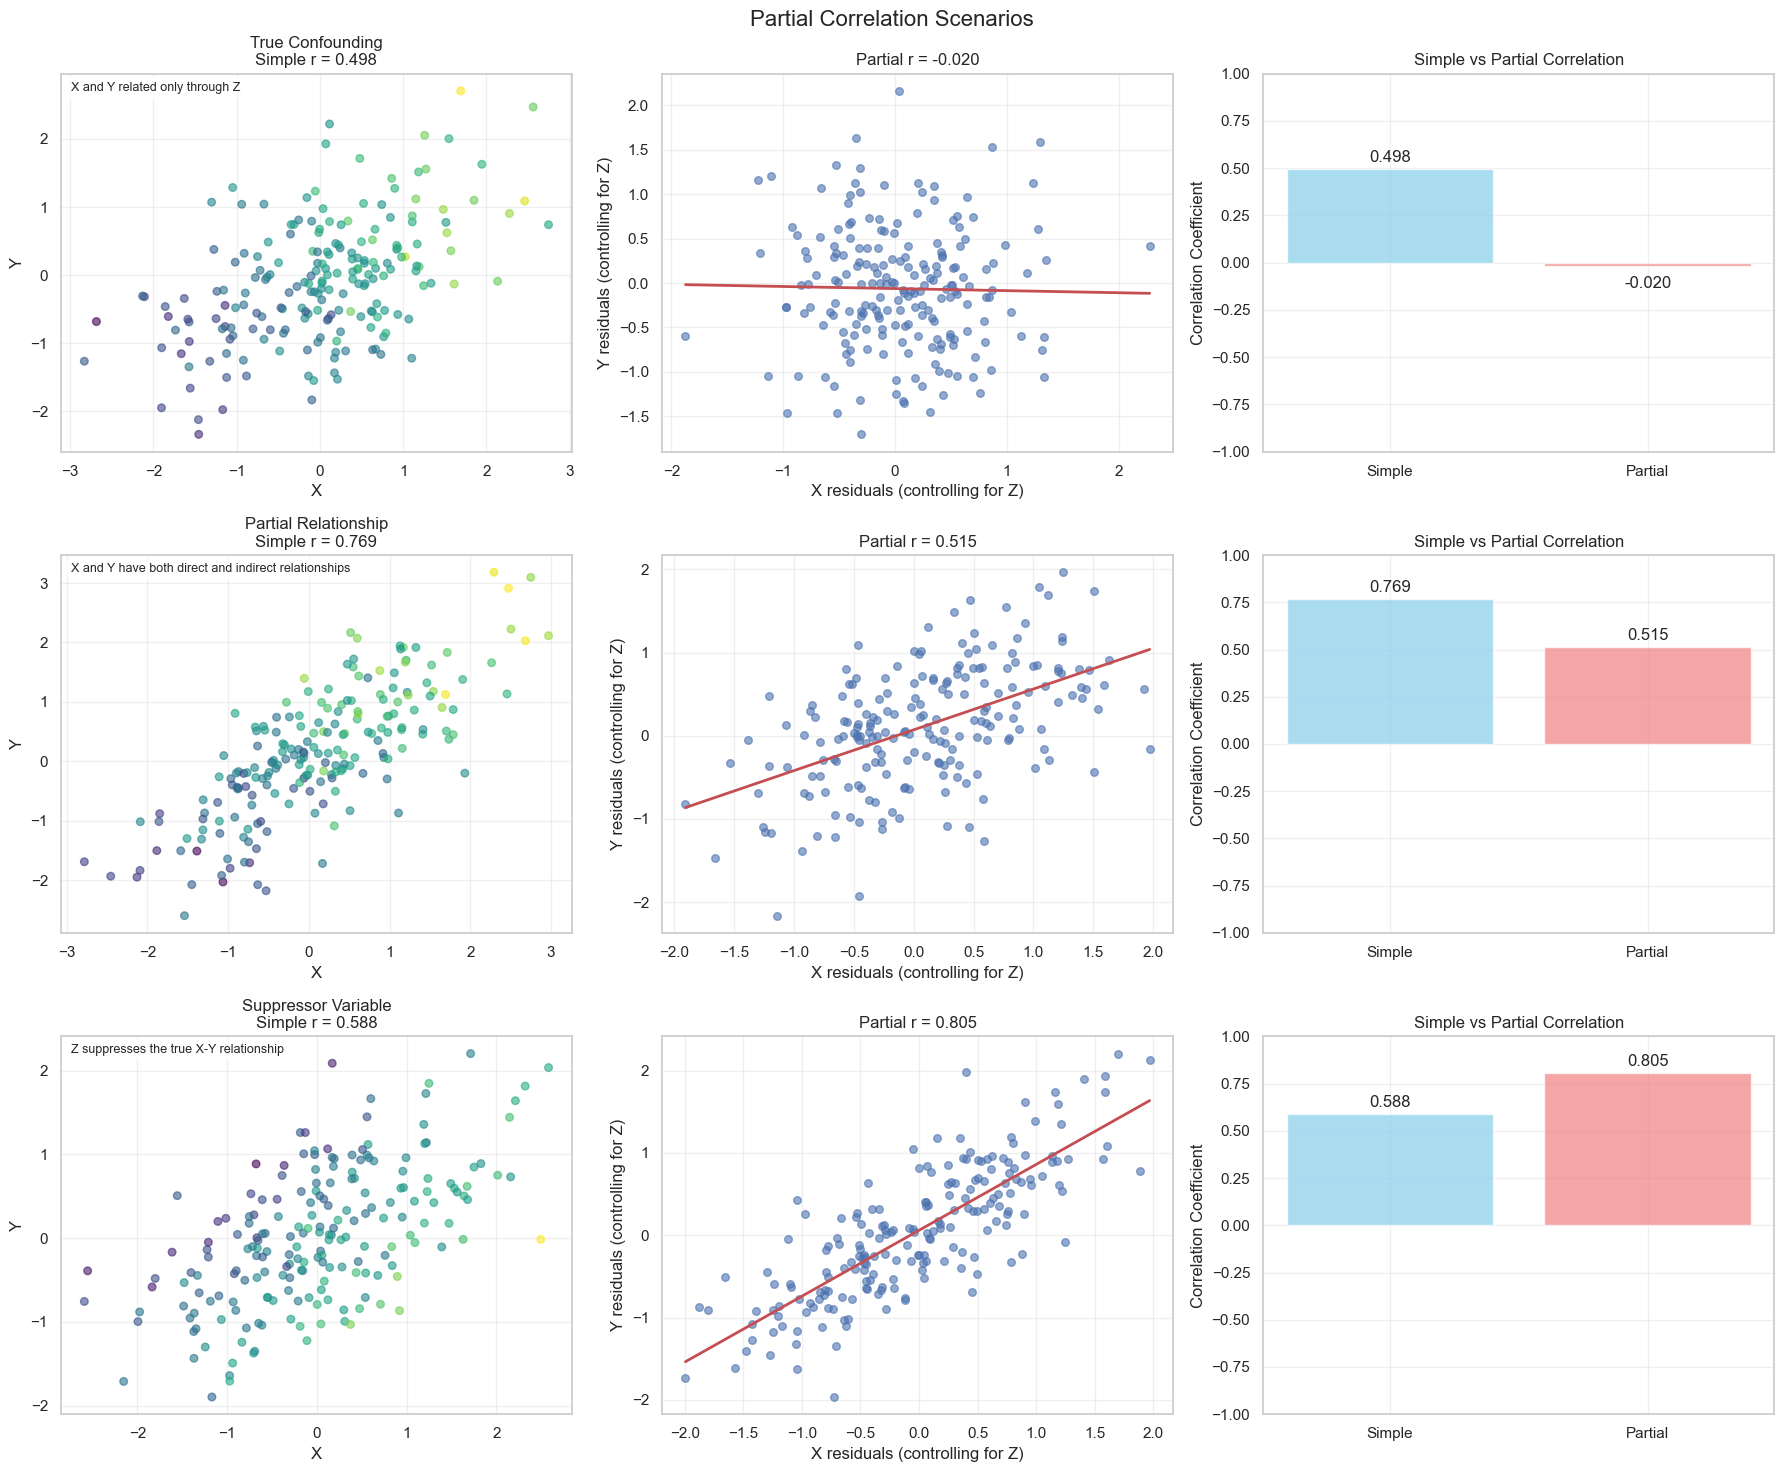

In [13]:
def demonstrate_partial_correlation_concepts():
    """
    Demonstrate partial correlation concepts with simulated data.
    """
    print(f"\n" + "=" * 70)
    print("PARTIAL CORRELATION CONCEPTS: SIMULATED EXAMPLES")
    print("=" * 70)

    np.random.seed(42)
    n = 200

    # Scenario 1: True confounding
    print(f"\nScenario 1: True Confounding")
    print("-" * 30)

    # Z (confounder) influences both X and Y
    z1 = np.random.normal(0, 1, n)
    x1 = 0.8 * z1 + np.random.normal(0, 0.6, n)  # X depends on Z
    y1 = 0.7 * z1 + np.random.normal(0, 0.7, n)  # Y depends on Z
    # X and Y are NOT directly related, only through Z

    # Scenario 2: Partial relationship
    print(f"Scenario 2: Partial Relationship")
    print("-" * 32)

    # Z influences both X and Y, but X and Y also have direct relationship
    z2 = np.random.normal(0, 1, n)
    x2 = 0.6 * z2 + np.random.normal(0, 0.8, n)  # X depends on Z
    y2 = 0.5 * z2 + 0.4 * x2 + np.random.normal(0, 0.6, n)  # Y depends on both Z and X

    # Scenario 3: Suppressor variable
    print(f"Scenario 3: Suppressor Variable")
    print("-" * 32)

    # Z suppresses the true X-Y relationship
    x3 = np.random.normal(0, 1, n)
    z3 = 0.6 * x3 + np.random.normal(0, 0.8, n)  # Z depends on X
    y3 = 0.8 * x3 - 0.5 * z3 + np.random.normal(0, 0.5, n)  # Y depends positively on X, negatively on Z

    scenarios = [
        ("True Confounding", x1, y1, z1, "X and Y related only through Z"),
        ("Partial Relationship", x2, y2, z2, "X and Y have both direct and indirect relationships"),
        ("Suppressor Variable", x3, y3, z3, "Z suppresses the true X-Y relationship")
    ]

    fig, axes = plt.subplots(3, 3, figsize=(18, 15))
    fig.suptitle('Partial Correlation Scenarios', fontsize=16)

    for i, (title, x, y, z, description) in enumerate(scenarios):
        # Calculate correlations
        r_xy_simple, _ = pearsonr(x, y)

        # Calculate partial correlation manually
        r_xz, _ = pearsonr(x, z)
        r_yz, _ = pearsonr(y, z)

        numerator = r_xy_simple - (r_xz * r_yz)
        denominator = np.sqrt((1 - r_xz**2) * (1 - r_yz**2))
        r_xy_partial = numerator / denominator if denominator != 0 else np.nan

        # Plot 1: X vs Y scatter plot
        axes[i, 0].scatter(x, y, alpha=0.6, s=30, c=z, cmap='viridis')
        axes[i, 0].set_xlabel('X')
        axes[i, 0].set_ylabel('Y')
        axes[i, 0].set_title(f'{title}\nSimple r = {r_xy_simple:.3f}')
        axes[i, 0].grid(True, alpha=0.3)

        # Plot 2: Partial correlation (residuals)
        # Regress X on Z, get residuals
        slope_xz = np.cov(x, z)[0, 1] / np.var(z)
        x_residuals = x - (slope_xz * z)

        # Regress Y on Z, get residuals
        slope_yz = np.cov(y, z)[0, 1] / np.var(z)
        y_residuals = y - (slope_yz * z)

        axes[i, 1].scatter(x_residuals, y_residuals, alpha=0.6, s=30)
        axes[i, 1].set_xlabel('X residuals (controlling for Z)')
        axes[i, 1].set_ylabel('Y residuals (controlling for Z)')
        axes[i, 1].set_title(f'Partial r = {r_xy_partial:.3f}')
        axes[i, 1].grid(True, alpha=0.3)

        # Add regression line to residuals plot
        if not np.isnan(r_xy_partial):
            z_line = np.polyfit(x_residuals, y_residuals, 1)
            p_line = np.poly1d(z_line)
            x_line = np.linspace(x_residuals.min(), x_residuals.max(), 100)
            axes[i, 1].plot(x_line, p_line(x_line), 'r-', linewidth=2)

        # Plot 3: Comparison bar chart
        correlations = [r_xy_simple, r_xy_partial]
        labels = ['Simple', 'Partial']
        colors = ['skyblue', 'lightcoral']

        bars = axes[i, 2].bar(labels, correlations, color=colors, alpha=0.7)
        axes[i, 2].set_ylabel('Correlation Coefficient')
        axes[i, 2].set_title('Simple vs Partial Correlation')
        axes[i, 2].grid(True, alpha=0.3)
        axes[i, 2].set_ylim(-1, 1)

        # Add value labels on bars
        for bar, corr in zip(bars, correlations):
            height = bar.get_height()
            axes[i, 2].text(bar.get_x() + bar.get_width()/2., height + 0.02 if height >= 0 else height - 0.05,
                           f'{corr:.3f}', ha='center', va='bottom' if height >= 0 else 'top')

        # Add scenario description
        axes[i, 0].text(0.02, 0.98, description, transform=axes[i, 0].transAxes,
                       bbox=dict(boxstyle='round', facecolor='white', alpha=0.8),
                       verticalalignment='top', fontsize=9)

        print(f"{title}:")
        print(f"  Simple correlation: {r_xy_simple:.3f}")
        print(f"  Partial correlation: {r_xy_partial:.3f}")
        print(f"  Difference: {r_xy_simple - r_xy_partial:.3f}")
        print(f"  Interpretation: {description}")
        print()

    plt.tight_layout()
    plt.show()

# Step 1: Demonstrate partial correlation concepts
print("\n Step 1: Demonstrating partial correlation concepts")
demonstrate_partial_correlation_concepts()


 EXECUTING PARTIAL CORRELATION ANALYSIS

 Step 2: Analyzing species effects on penguin morphology

SPECIES EFFECTS ON PENGUIN MORPHOLOGY CORRELATIONS
Species dummy variables created:
  • species_Chinstrap
  • species_Gentoo

Analyzing relationships with and without species control:

Bill length ↔ Body mass
-----------------------

Calculating partial correlation:
X variable: bill_length_mm
Y variable: body_mass_g
Controlling for: species_Chinstrap, species_Gentoo
Sample size: 333

Method 1: Regression Residuals Approach
---------------------------------------------
Partial correlation (residuals method): 0.5823
P-value: 0.000000

Significance test:
Degrees of freedom: 329
t-statistic: 12.9906
p-value: 0.000000
Effect size: Large

Summary:
Simple correlation:    r = 0.5895 (p = 0.0000)
Partial correlation:   r = 0.5823 (p = 0.0000)
Difference:            Δr = 0.0072
Interpretation: Small species effect - relationship is largely within-species

Flipper length ↔ Body mass
---------------

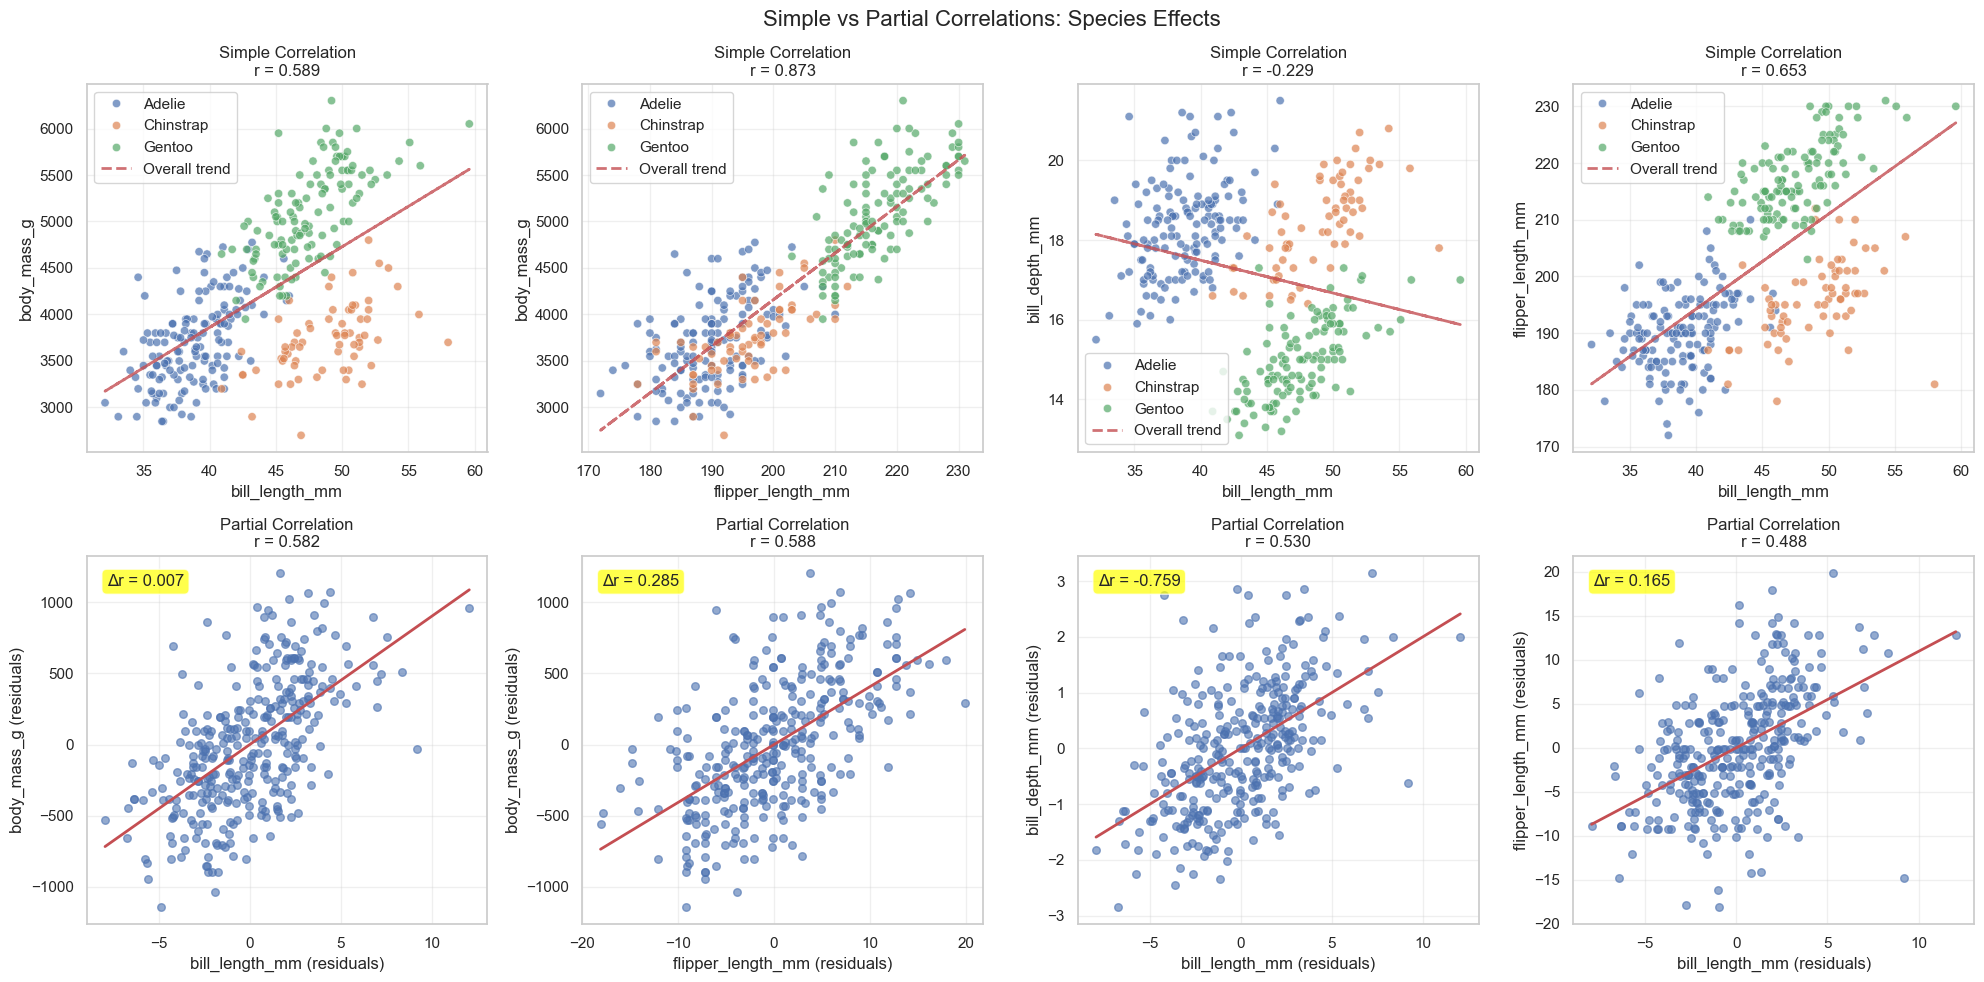


 Step 3: Within-species correlation analysis

WITHIN-SPECIES CORRELATION ANALYSIS
Analyzing correlations within each species:

ADELIE PENGUINS
Sample size: 146

Correlation matrix:
                   bill_length_mm  bill_depth_mm  flipper_length_mm  \
bill_length_mm              1.000          0.386              0.332   
bill_depth_mm               0.386          1.000              0.311   
flipper_length_mm           0.332          0.311              1.000   
body_mass_g                 0.544          0.580              0.465   

                   body_mass_g  
bill_length_mm           0.544  
bill_depth_mm            0.580  
flipper_length_mm        0.465  
body_mass_g              1.000  

CHINSTRAP PENGUINS
Sample size: 68

Correlation matrix:
                   bill_length_mm  bill_depth_mm  flipper_length_mm  \
bill_length_mm              1.000          0.654              0.472   
bill_depth_mm               0.654          1.000              0.580   
flipper_length_mm          

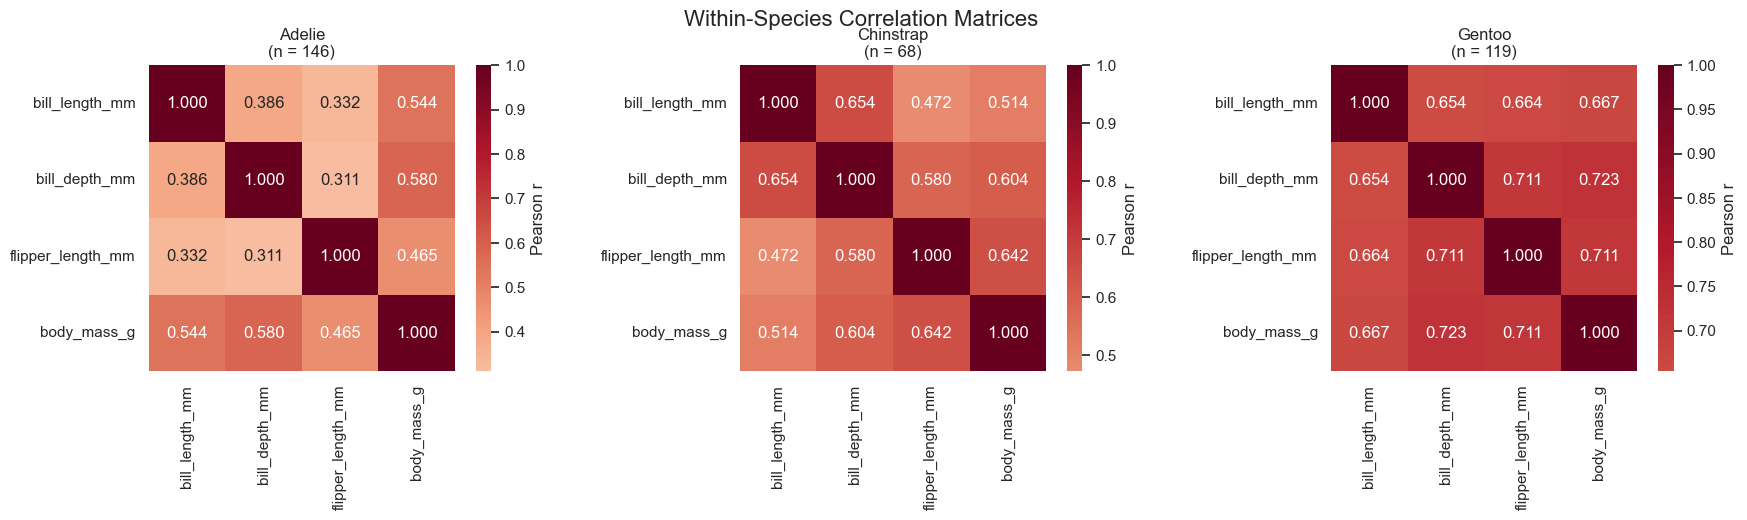


Comparison across species:
------------------------------
                                      Adelie Chinstrap    Gentoo
bill_length_mm ↔ bill_depth_mm      0.385813  0.653536  0.654023
bill_length_mm ↔ flipper_length_mm  0.332274  0.471607  0.664205
bill_length_mm ↔ body_mass_g        0.544276  0.513638   0.66673
bill_depth_mm ↔ flipper_length_mm   0.310897  0.580143  0.710642
bill_depth_mm ↔ body_mass_g         0.580156  0.604498  0.722967
flipper_length_mm ↔ body_mass_g     0.464854  0.641559  0.711305

Variability in correlations across species:
---------------------------------------------
bill_length_mm ↔ bill_depth_mm     : variance = 0.0160, range = 0.268
bill_length_mm ↔ flipper_length_mm : variance = 0.0185, range = 0.332
bill_length_mm ↔ body_mass_g       : variance = 0.0044, range = 0.153
bill_depth_mm ↔ flipper_length_mm  : variance = 0.0277, range = 0.400
bill_depth_mm ↔ body_mass_g        : variance = 0.0039, range = 0.143
flipper_length_mm ↔ body_mass_g    : variance

In [14]:
def calculate_partial_correlation(data, x_var, y_var, control_vars):
    """
    Calculate partial correlation between two variables controlling for others.

    """
    print(f"\nCalculating partial correlation:")
    print(f"X variable: {x_var}")
    print(f"Y variable: {y_var}")
    print(f"Controlling for: {', '.join(control_vars)}")

    # Get clean data
    all_vars = [x_var, y_var] + control_vars
    clean_data = data[all_vars].dropna()
    n = len(clean_data)

    print(f"Sample size: {n}")

    # Method 1: Using regression residuals (most intuitive)
    print(f"\nMethod 1: Regression Residuals Approach")
    print("-" * 45)

    # Step 1: Regress X on control variables, get residuals
    X_controls = clean_data[control_vars]
    X_target = clean_data[x_var]

    model_x = LinearRegression()
    model_x.fit(X_controls, X_target)
    x_residuals = X_target - model_x.predict(X_controls)

    # Step 2: Regress Y on control variables, get residuals
    Y_target = clean_data[y_var]

    model_y = LinearRegression()
    model_y.fit(X_controls, Y_target)
    y_residuals = Y_target - model_y.predict(X_controls)

    # Step 3: Correlate the residuals
    partial_r_residuals, p_value_residuals = pearsonr(x_residuals, y_residuals)

    print(f"Partial correlation (residuals method): {partial_r_residuals:.4f}")
    print(f"P-value: {p_value_residuals:.6f}")

    # Method 2: Direct formula for single control variable:
    # The direct formula method can only handle one control variable at a time.
    # But in our code we are Controlling for: species_Chinstrap, species_Gentoo
    # So this method will be skipped
    if len(control_vars) == 1:
        print(f"\nMethod 2: Direct Formula (Single Control)")
        print("-" * 45)

        z_var = control_vars[0]

        # Calculate simple correlations
        r_xy, _ = pearsonr(clean_data[x_var], clean_data[y_var])
        r_xz, _ = pearsonr(clean_data[x_var], clean_data[z_var])
        r_yz, _ = pearsonr(clean_data[y_var], clean_data[z_var])

        # Apply partial correlation formula
        numerator = r_xy - (r_xz * r_yz)
        denominator = np.sqrt((1 - r_xz**2) * (1 - r_yz**2))

        if denominator != 0:
            partial_r_formula = numerator / denominator
        else:
            partial_r_formula = np.nan

        print(f"Simple correlations:")
        print(f"  r({x_var}, {y_var}) = {r_xy:.4f}")
        print(f"  r({x_var}, {z_var}) = {r_xz:.4f}")
        print(f"  r({y_var}, {z_var}) = {r_yz:.4f}")
        print(f"Partial correlation (formula): {partial_r_formula:.4f}")

        # Verify methods agree
        diff = abs(partial_r_residuals - partial_r_formula)
        print(f"Difference between methods: {diff:.6f}")

    # Calculate degrees of freedom and significance test
    df = n - len(control_vars) - 2

    # t-statistic for partial correlation
    if abs(partial_r_residuals) < 1:
        t_stat = partial_r_residuals * np.sqrt(df / (1 - partial_r_residuals**2))
        p_value_t = 2 * (1 - stats.t.cdf(abs(t_stat), df))
    else:
        t_stat = np.inf
        p_value_t = 0.0

    print(f"\nSignificance test:")
    print(f"Degrees of freedom: {df}")
    print(f"t-statistic: {t_stat:.4f}")
    print(f"p-value: {p_value_t:.6f}")

    # Effect size interpretation
    if abs(partial_r_residuals) >= 0.5:
        effect_size = "Large"
    elif abs(partial_r_residuals) >= 0.3:
        effect_size = "Medium"
    elif abs(partial_r_residuals) >= 0.1:
        effect_size = "Small"
    else:
        effect_size = "Negligible"

    print(f"Effect size: {effect_size}")

    return {
        'partial_correlation': partial_r_residuals,
        'p_value': p_value_residuals,
        't_statistic': t_stat,
        'degrees_of_freedom': df,
        'effect_size': effect_size,
        'sample_size': n,
        'x_residuals': x_residuals,
        'y_residuals': y_residuals,
        'method_comparison': {
            'residuals_method': partial_r_residuals,
            'formula_method': partial_r_formula if len(control_vars) == 1 else None
        }
    }

# one-hot encoding categorical variables
def create_dummy_variables(data, categorical_var):
    """
    Create dummy variables for categorical variable to use in partial correlation.

    """
    # Create dummy variables (drop first to avoid multicollinearity): one-hot encoding categorical variables
    dummies = pd.get_dummies(data[categorical_var], prefix=categorical_var, drop_first=True)
    return dummies

def analyze_species_effects(data, continuous_vars):
    """
    Analyze how species affects correlations between morphological variables.

    """
    print(f"\n" + "=" * 70)
    print("SPECIES EFFECTS ON PENGUIN MORPHOLOGY CORRELATIONS")
    print("=" * 70)

    # Create species dummy variables
    species_dummies = create_dummy_variables(data, 'species')

    # Combine with continuous variables
    analysis_data = pd.concat([data[continuous_vars], species_dummies], axis=1)
    analysis_data = analysis_data.dropna()

    print(f"Species dummy variables created:")
    for col in species_dummies.columns:
        print(f"  • {col}")

    # Analyze key morphological relationships
    key_relationships = [
        ('bill_length_mm', 'body_mass_g', 'Bill length ↔ Body mass'),
        ('flipper_length_mm', 'body_mass_g', 'Flipper length ↔ Body mass'),
        ('bill_length_mm', 'bill_depth_mm', 'Bill length ↔ Bill depth'),
        ('bill_length_mm', 'flipper_length_mm', 'Bill length ↔ Flipper length')
    ]

    results = {}

    print(f"\nAnalyzing relationships with and without species control:")
    print("=" * 55)

    for x_var, y_var, description in key_relationships:
        print(f"\n{description}")
        print("-" * len(description))


        # Simple correlation (no control) - ensure same sample as partial correlation
        clean_pair_data = analysis_data[[x_var, y_var]].dropna()
        simple_r, simple_p = pearsonr(clean_pair_data[x_var], clean_pair_data[y_var])

        # Partial correlation controlling for species
        control_vars = list(species_dummies.columns)
        partial_result = calculate_partial_correlation(analysis_data, x_var, y_var, control_vars)

        # Calculate the difference
        difference = simple_r - partial_result['partial_correlation']

        print(f"\nSummary:")
        print(f"Simple correlation:    r = {simple_r:.4f} (p = {simple_p:.4f})")
        print(f"Partial correlation:   r = {partial_result['partial_correlation']:.4f} (p = {partial_result['p_value']:.4f})")
        print(f"Difference:            Δr = {difference:.4f}")

        # Interpretation
        if abs(difference) > 0.2:
            interpretation = "Large species effect - species is a major confounder"
        elif abs(difference) > 0.1:
            interpretation = "Moderate species effect - some confounding present"
        else:
            interpretation = "Small species effect - relationship is largely within-species"

        print(f"Interpretation: {interpretation}")

        results[f"{x_var}_{y_var}"] = {
            'description': description,
            'simple_correlation': simple_r,
            'simple_p_value': simple_p,
            'partial_correlation': partial_result['partial_correlation'],
            'partial_p_value': partial_result['p_value'],
            'difference': difference,
            'interpretation': interpretation,
            'x_residuals': partial_result['x_residuals'],
            'y_residuals': partial_result['y_residuals']
        }

    # Create comprehensive visualization
    fig, axes = plt.subplots(2, len(key_relationships), figsize=(5*len(key_relationships), 10))
    fig.suptitle('Simple vs Partial Correlations: Species Effects', fontsize=16)

    for i, (x_var, y_var, description) in enumerate(key_relationships):
        result = results[f"{x_var}_{y_var}"]

        # Top row: Simple correlations with species colored
        sns.scatterplot(data=data, x=x_var, y=y_var, hue='species', ax=axes[0, i], alpha=0.7)

        # Add overall regression line
        x_vals = data[x_var].dropna()
        y_vals = data[y_var].dropna()
        z = np.polyfit(x_vals, y_vals, 1)
        p = np.poly1d(z)
        axes[0, i].plot(x_vals, p(x_vals), "r--", alpha=0.8, linewidth=2, label='Overall trend')

        axes[0, i].set_title(f'Simple Correlation\nr = {result["simple_correlation"]:.3f}')
        axes[0, i].legend()
        axes[0, i].grid(True, alpha=0.3)

        # Bottom row: Partial correlation (residuals plot)
        axes[1, i].scatter(result['x_residuals'], result['y_residuals'], alpha=0.6, s=30)

        # Add regression line for residuals
        z_res = np.polyfit(result['x_residuals'], result['y_residuals'], 1)
        p_res = np.poly1d(z_res)
        x_res_line = np.linspace(result['x_residuals'].min(), result['x_residuals'].max(), 100)
        axes[1, i].plot(x_res_line, p_res(x_res_line), "r-", linewidth=2)

        axes[1, i].set_title(f'Partial Correlation\nr = {result["partial_correlation"]:.3f}')
        axes[1, i].set_xlabel(f'{x_var} (residuals)')
        axes[1, i].set_ylabel(f'{y_var} (residuals)')
        axes[1, i].grid(True, alpha=0.3)

        # Add difference annotation
        diff_text = f'Δr = {result["difference"]:.3f}'
        axes[1, i].text(0.05, 0.95, diff_text, transform=axes[1, i].transAxes,
                       bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.7),
                       verticalalignment='top')

    plt.tight_layout()
    plt.show()

    return results

def perform_within_species_correlations(data, continuous_vars):
    """
    Calculate correlations within each species separately.
    """
    print(f"\n" + "=" * 70)
    print("WITHIN-SPECIES CORRELATION ANALYSIS")
    print("=" * 70)

    species_list = data['species'].unique()
    within_species_results = {}

    print(f"Analyzing correlations within each species:")

    for species in species_list:
        print(f"\n{species.upper()} PENGUINS")
        print("=" * (len(species) + 9))

        species_data = data[data['species'] == species][continuous_vars].dropna()
        n_species = len(species_data)

        print(f"Sample size: {n_species}")

        # Calculate correlation matrix for this species
        species_corr = species_data.corr()

        print(f"\nCorrelation matrix:")
        print(species_corr.round(3))

        # Store results
        within_species_results[species] = {
            'correlation_matrix': species_corr,
            'sample_size': n_species,
            'data': species_data
        }

    # Create comparison visualization
    fig, axes = plt.subplots(1, len(species_list), figsize=(6*len(species_list), 5))
    fig.suptitle('Within-Species Correlation Matrices', fontsize=16)

    # Ensure axes is a list for consistent indexing
    if len(species_list) == 1:
        axes = [axes]

    for i, species in enumerate(species_list):
        corr_matrix = within_species_results[species]['correlation_matrix']

        # Create mask for upper triangle
        #mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

        sns.heatmap(corr_matrix,
                    #mask=mask,
                    annot=True, cmap='RdBu_r', center=0,
                   square=True, fmt='.3f', ax=axes[i],
                   cbar_kws={'label': 'Pearson r'})

        axes[i].set_title(f'{species}\n(n = {within_species_results[species]["sample_size"]})')

    plt.tight_layout()
    plt.show()

    # Compare correlations across species
    print(f"\nComparison across species:")
    print("-" * 30)

    # Get all unique variable pairs
    var_pairs = []
    for i in range(len(continuous_vars)):
        for j in range(i+1, len(continuous_vars)):
            var_pairs.append((continuous_vars[i], continuous_vars[j]))

    comparison_df = pd.DataFrame(index=[f"{var1} ↔ {var2}" for var1, var2 in var_pairs],
                                columns=species_list)

    for var1, var2 in var_pairs:
        pair_name = f"{var1} ↔ {var2}"
        for species in species_list:
            corr_val = within_species_results[species]['correlation_matrix'].loc[var1, var2]
            comparison_df.loc[pair_name, species] = corr_val

    print(comparison_df.round(3))

    # Calculate variance in correlations across species
    print(f"\nVariability in correlations across species:")
    print("-" * 45)

    for pair_name in comparison_df.index:
        correlations = comparison_df.loc[pair_name].values
        var_corr = np.var(correlations)
        range_corr = np.max(correlations) - np.min(correlations)

        print(f"{pair_name:<35}: variance = {var_corr:.4f}, range = {range_corr:.3f}")

    return within_species_results, comparison_df


# Execute Part 3 Analysis
print("\n EXECUTING PARTIAL CORRELATION ANALYSIS")
print("=" * 50)

# For demonstration, let's use the penguin data
test_data = penguins_clean.head()


# Step 2: Analyze species effects on correlations
print("\n Step 2: Analyzing species effects on penguin morphology")
species_effects = analyze_species_effects(penguins_clean, continuous_vars)

# Step 3: Within-species correlation analysis
print("\n Step 3: Within-species correlation analysis")
within_species_results, species_comparison = perform_within_species_correlations(penguins_clean, continuous_vars)



### Partial Correlation Analysis Results Summary

#### Key Findings: Species Effects on Penguin Morphology

- Three Distinct Patterns Emerged
    * 1. Minimal Species Effect: Bill Length $\leftrightarrow$ Body Mass
        * Simple correlation: $r = 0.589$
        * Partial correlation: $r = 0.582$ (controlling for species)
        * Difference: $\Delta r = 0.007$ (almost no change!)
        * Interpretation: This relationship is genuinely within-species. The correlation we see is not just due to species differences.
    * 2. Moderate Species Effect: Bill Length $\leftrightarrow$ Flipper Length
        * Simple correlation: $r = 0.653$
        * Partial correlation: $r = 0.488$
        * Difference: $\Delta r = 0.165$ (noticeable reduction)
        * Interpretation: Some of the apparent relationship is due to species differences, but a meaningful within-species relationship remains.
    * 3. Major Species Effect: Two Dramatic Examples
        * Flipper Length $\leftrightarrow$ Body Mass:
            - Simple correlation: $r = 0.873$ (very strong!)
            - Partial correlation: $r = 0.588$ (moderate)
            - Difference: $\Delta r = 0.285$ (huge reduction!)
            - Interpretation: Much of this "relationship" was actually just reflecting that larger species (Gentoo) have both longer flippers AND heavier bodies.
        * Bill Length $\leftrightarrow$ Bill Depth (Most dramatic):
            - Simple correlation: $r = -0.229$ (negative relationship!)
            - Partial correlation: $r = 0.530$ (positive relationship!)
            - Difference: $\Delta r = -0.759$ (complete reversal!)
            - Interpretation: This is a classic "suppressor variable" effect (Simpson's Paradox). Between species, longer bills tend to be shallower, but within species, longer bills are actually deeper.

---

#### What the Visualizations Show

- Figure 1: Theoretical Examples
    * The simulated data demonstrates three scenarios:
        * True Confounding: Simple $r = 0.498 \rightarrow$ Partial $r = -0.020$ (relationship disappears).
        * Partial Relationship: Simple $r = 0.769 \rightarrow$ Partial $r = 0.515$ (relationship weakens but persists).
        * Suppressor Variable: Simple $r = 0.588 \rightarrow$ Partial $r = 0.805$ (relationship strengthens).

- Figure 2: Real Penguin Data
    * The upper panels show clear species clustering — you can see three distinct groups (Adelie, Chinstrap, Gentoo) in each scatter plot.
    * The lower panels (residuals) show the within-species patterns after removing species effects.
    * Notice how the yellow $\Delta r$ values reveal the magnitude of species confounding.

- Figure 3: Within-Species Patterns
    * The correlation matrices reveal interesting species differences:
        * Gentoo penguins show the strongest correlations overall (darker red colors).
        * Adelie penguins show weaker correlations (lighter colors).
        * Bill length $\leftrightarrow$ bill depth varies dramatically: Adelie ($r = 0.386$) vs. Chinstrap/Gentoo ($r \approx 0.654$).
----

----
### Advanced Correlation Analysis 

### 1. Overview & Core Purpose
- Core Objective
    * Adding statistical rigor to correlation analysis by moving beyond single point estimates (e.g., simply stating $r = 0.653$).
- Key Topics Covered
    * Calculating 95% confidence intervals for correlation coefficients.
    * Resolving the multiple testing problem using adjusted $p$-value methods.
    * Visualizing correlations via hierarchical clustering and dendrograms.
    * Non-parametric validation using bootstrap resampling.
    * Conducting statistical power analysis for correlation sample sizes.
    * Standardized reporting of correlation results (e.g., APA format).

### 2. Confidence Intervals & Fisher’s $Z$-Transformation
- fisher z transformation is a statistical method used to convert a correlation cofficient(r) into Z values.
- why do we use it ?
    * Correlation coefficients are limited between -1 and +1, and their sampling distribution is not normally distributed, especially when the correlation is far from zero.
    * fisher makes the distribution normal , which is eaise to claculate confidence interval for correlation,perform power analysis for correlation , test weather correlation are partially different.
- The Limitation of Point Estimates
    * Reporting a single correlation coefficient ($r = 0.653$) fails to convey sampling uncertainty.
    * Adding confidence intervals provides a lower and upper range (e.g., $r = 0.653$, 95% CI $[0.587, 0.711]$).
- The Non-Normality Issue
    * Sample correlation coefficients ($r$) are bounded between $-1$ and $+1$ and are often not normally distributed, making direct confidence interval calculations inaccurate.
- Fisher’s $Z$-Transformation Solution
    1. Convert $r$ to $Z$-Space: Transforms $r$ into an approximately normally distributed variable using the formula:
       $$Z = 0.5 \cdot \ln\left(\frac{1 + r}{1 - r}\right)$$
    2. Compute Standard Error: Calculate the standard error ($SE$) in $Z$-space based on sample size $N$:
       $$SE_Z = \frac{1}{\sqrt{N - 3}}$$
    3. Establish $Z$-Space Bounds: Subtract and add the critical value (e.g., $1.96$ for a 95% confidence interval) multiplied by $SE_Z$ from $Z$ to determine lower ($Z_{\text{lower}}$) and upper ($Z_{\text{upper}}$) confidence bounds:
       $$Z_{\text{lower}} = Z - 1.96 \cdot SE_Z$$
       $$Z_{\text{upper}} = Z + 1.96 \cdot SE_Z$$
    4. Inverse Transformation Back to $r$-Space: Convert the $Z$-space limits back to the original $r$ scale using the inverse Fisher $Z$ equation:
       $$r = \frac{e^{2Z} - 1}{e^{2Z} + 1}$$

### 3. The Multiple Testing Problem & Correction Methods
- The Problem
    * When testing multiple pairwise correlations simultaneously, the risk of detecting false positives (Type I error) accumulates rapidly.
- Mathematical Cumulative Error Risk
    * For a single test at significance level $\alpha = 0.05$, there is a 5% chance of a false discovery.
    * Across $n = 6$ unique pairwise tests (e.g., pair combinations of Palmer Penguins features), the overall probability of finding at least one false positive is:
      $$\text{Family-Wise Error Rate} = 1 - (1 - \alpha)^n = 1 - (1 - 0.05)^6 \approx 26.5\%$$
- Correction Methods (available in `statsmodels.stats.multitest`)
    * `Bonferroni Correction`: The most conservative method. Divides $\alpha$ by the number of tests ($n$). For $n = 6$, the new significance threshold becomes $\alpha_{\text{adj}} = \frac{0.05}{6} \approx 0.00833$. It rarely produces false positives but increases the risk of missing real relationships.
    * `Holm-Bonferroni (Holm)`: A step-down sequential procedure that is less conservative than Bonferroni while strictly controlling the family-wise error rate.
    * `False Discovery Rate (FDR / Benjamini-Hochberg & Benjamini-Yekutieli)`: Controls the expected proportion of false discoveries among rejected hypotheses rather than family-wise error rate, offering higher statistical power.
- Palmer Penguins Dataset Result
    * Testing all 6 pairwise feature combinations across 333 complete observations revealed that all 6 correlations remained statistically significant ($p < 0.001$) even after applying Bonferroni, Holm, and FDR corrections.

### 4. Hierarchical Clustering of Correlations
- Purpose
    * Groups variables with similar correlation profiles together and reorders the correlation matrix heatmap to highlight structural patterns.
- Distance Metric Transformation
    * Converts correlation values ($r$) into distance metrics ($D$) using absolute values:
      $$D = 1 - |r|$$
    * Highly correlated variables ($r \approx 1.0$) yield distances near $0.0$ (clustered close together), while weak correlations yield distances near $1.0$.
- Implementation Protocol
    * Uses `scipy.cluster.hierarchy` linkage algorithms (e.g., Ward's method).
    * Converts the 2D correlation matrix into a condensed 1D distance array (excluding the zero-diagonal) as expected by SciPy linkage functions.
- Dendrogram & Reordered Heatmap Output
    * Cluster Findings: In the Palmer Penguins dataset, flipper length and body mass display the shortest distance (highest correlation, $r = 0.873$) and cluster tightly together.
    * Secondary Grouping: The flipper length–body mass cluster joins with bill length, whereas bill depth remains the most distinct variable ($\text{distance} \approx 0.7$).

### 5. Bootstrap Confidence Intervals for Correlation
- Concept
    * A non-parametric resampling technique that repeatedly draws random samples with replacement from the original dataset ($N = 333$) to empirically evaluate correlation stability and uncertainty.
    * it is technique used to check how stable and reliable our correlation coefficient is.
    * bootstrap Resampling -> erpeatedly creating new samples form your origina dataset. we select `observations with replacements`.
- Step-by-Step Workflow
    1. Compute the original correlation coefficient $r$ from the dataset.
    2. Resample $N$ observations with replacement $B = 1,000$ times.
    3. Calculate $r$ for each bootstrap iteration to generate an empirical distribution.
    4. Extract percentile bounds (e.g., 2.5th to 97.5th percentiles) to define the 95% bootstrap confidence interval.
    5. Check for bootstrap bias (the difference between the original correlation and the mean of the bootstrap distribution).
- Penguins Result
    * For flipper length vs. body mass, the original $r$ ($0.873$) and the bootstrap mean $r$ ($0.873$) were virtually identical, demonstrating zero bootstrap bias.
    * The bootstrap confidence intervals aligned closely with Fisher's $Z$-transformed intervals, and a Q-Q plot confirmed that the bootstrap correlation distribution was normally distributed.

### 6. Statistical Power Analysis for Correlation
- Purpose
    * Determines the sample size ($N$) required to achieve a target statistical power (typically 80% or $0.80$) for a given correlation magnitude at $\alpha = 0.05$.
- Sample Size & Effect Size Dynamics
    * Strong Correlation ($r = 0.8$): Requires fewer than 20 observations to reach 80% power.
    * Moderate Correlation ($r = 0.3$): Requires approximately 75 to 90 observations to achieve 80% power.
    * Weak Correlation ($r = 0.2$): Requires approximately 200 observations to reach 80% power.
- Dataset Evaluation
    * With $N = 333$ observations, the Palmer Penguins dataset easily exceeds the sample size needed to detect moderate-to-weak correlations with $> 80\%$ power.

### 7. Reporting Guidelines & Formats
- Standard Informal Format
    * Example: *"There was a small negative correlation between bill length and bill depth in mm ($r = -0.229, N = 333$)"*.
- Formal APA Style Format
    * Example: *"Bill length and bill depth were significantly correlated, $r(331) = -0.229, p < 0.001, 95\%\text{ CI } [-0.328, -0.124]$"*.
- Components
    * Degrees of freedom ($df = N - 2$): Listed in parentheses following $r$ (e.g., $333 - 2 = 331$).
    * Point estimate ($r$), $p$-value, and 95% confidence interval bounds $[LL, UL]$.
    * Confirmation of whether the correlation survived multiple testing corrections.


 EXECUTING ADVANCED CORRELATION ANALYSIS

 Step 1: Comprehensive correlation matrix analysis with confidence intervals

COMPREHENSIVE CORRELATION MATRIX ANALYSIS
Calculating correlations with 95% confidence intervals:
------------------------------------------------------------
bill_length_mm ↔ bill_depth_mm:
  r =  -0.229 [-0.328, -0.124], p =  0.0000, n = 333
bill_length_mm ↔ flipper_length_mm:
  r =   0.653 [ 0.587,  0.711], p =  0.0000, n = 333
bill_length_mm ↔ body_mass_g:
  r =   0.589 [ 0.515,  0.655], p =  0.0000, n = 333
bill_depth_mm ↔ flipper_length_mm:
  r =  -0.578 [-0.645, -0.501], p =  0.0000, n = 333
bill_depth_mm ↔ body_mass_g:
  r =  -0.472 [-0.552, -0.384], p =  0.0000, n = 333
flipper_length_mm ↔ body_mass_g:
  r =   0.873 [ 0.845,  0.896], p =  0.0000, n = 333

Correlation Matrix:
--------------------
                   bill_length_mm  bill_depth_mm  flipper_length_mm  \
bill_length_mm              1.000         -0.229              0.653   
bill_depth_mm          

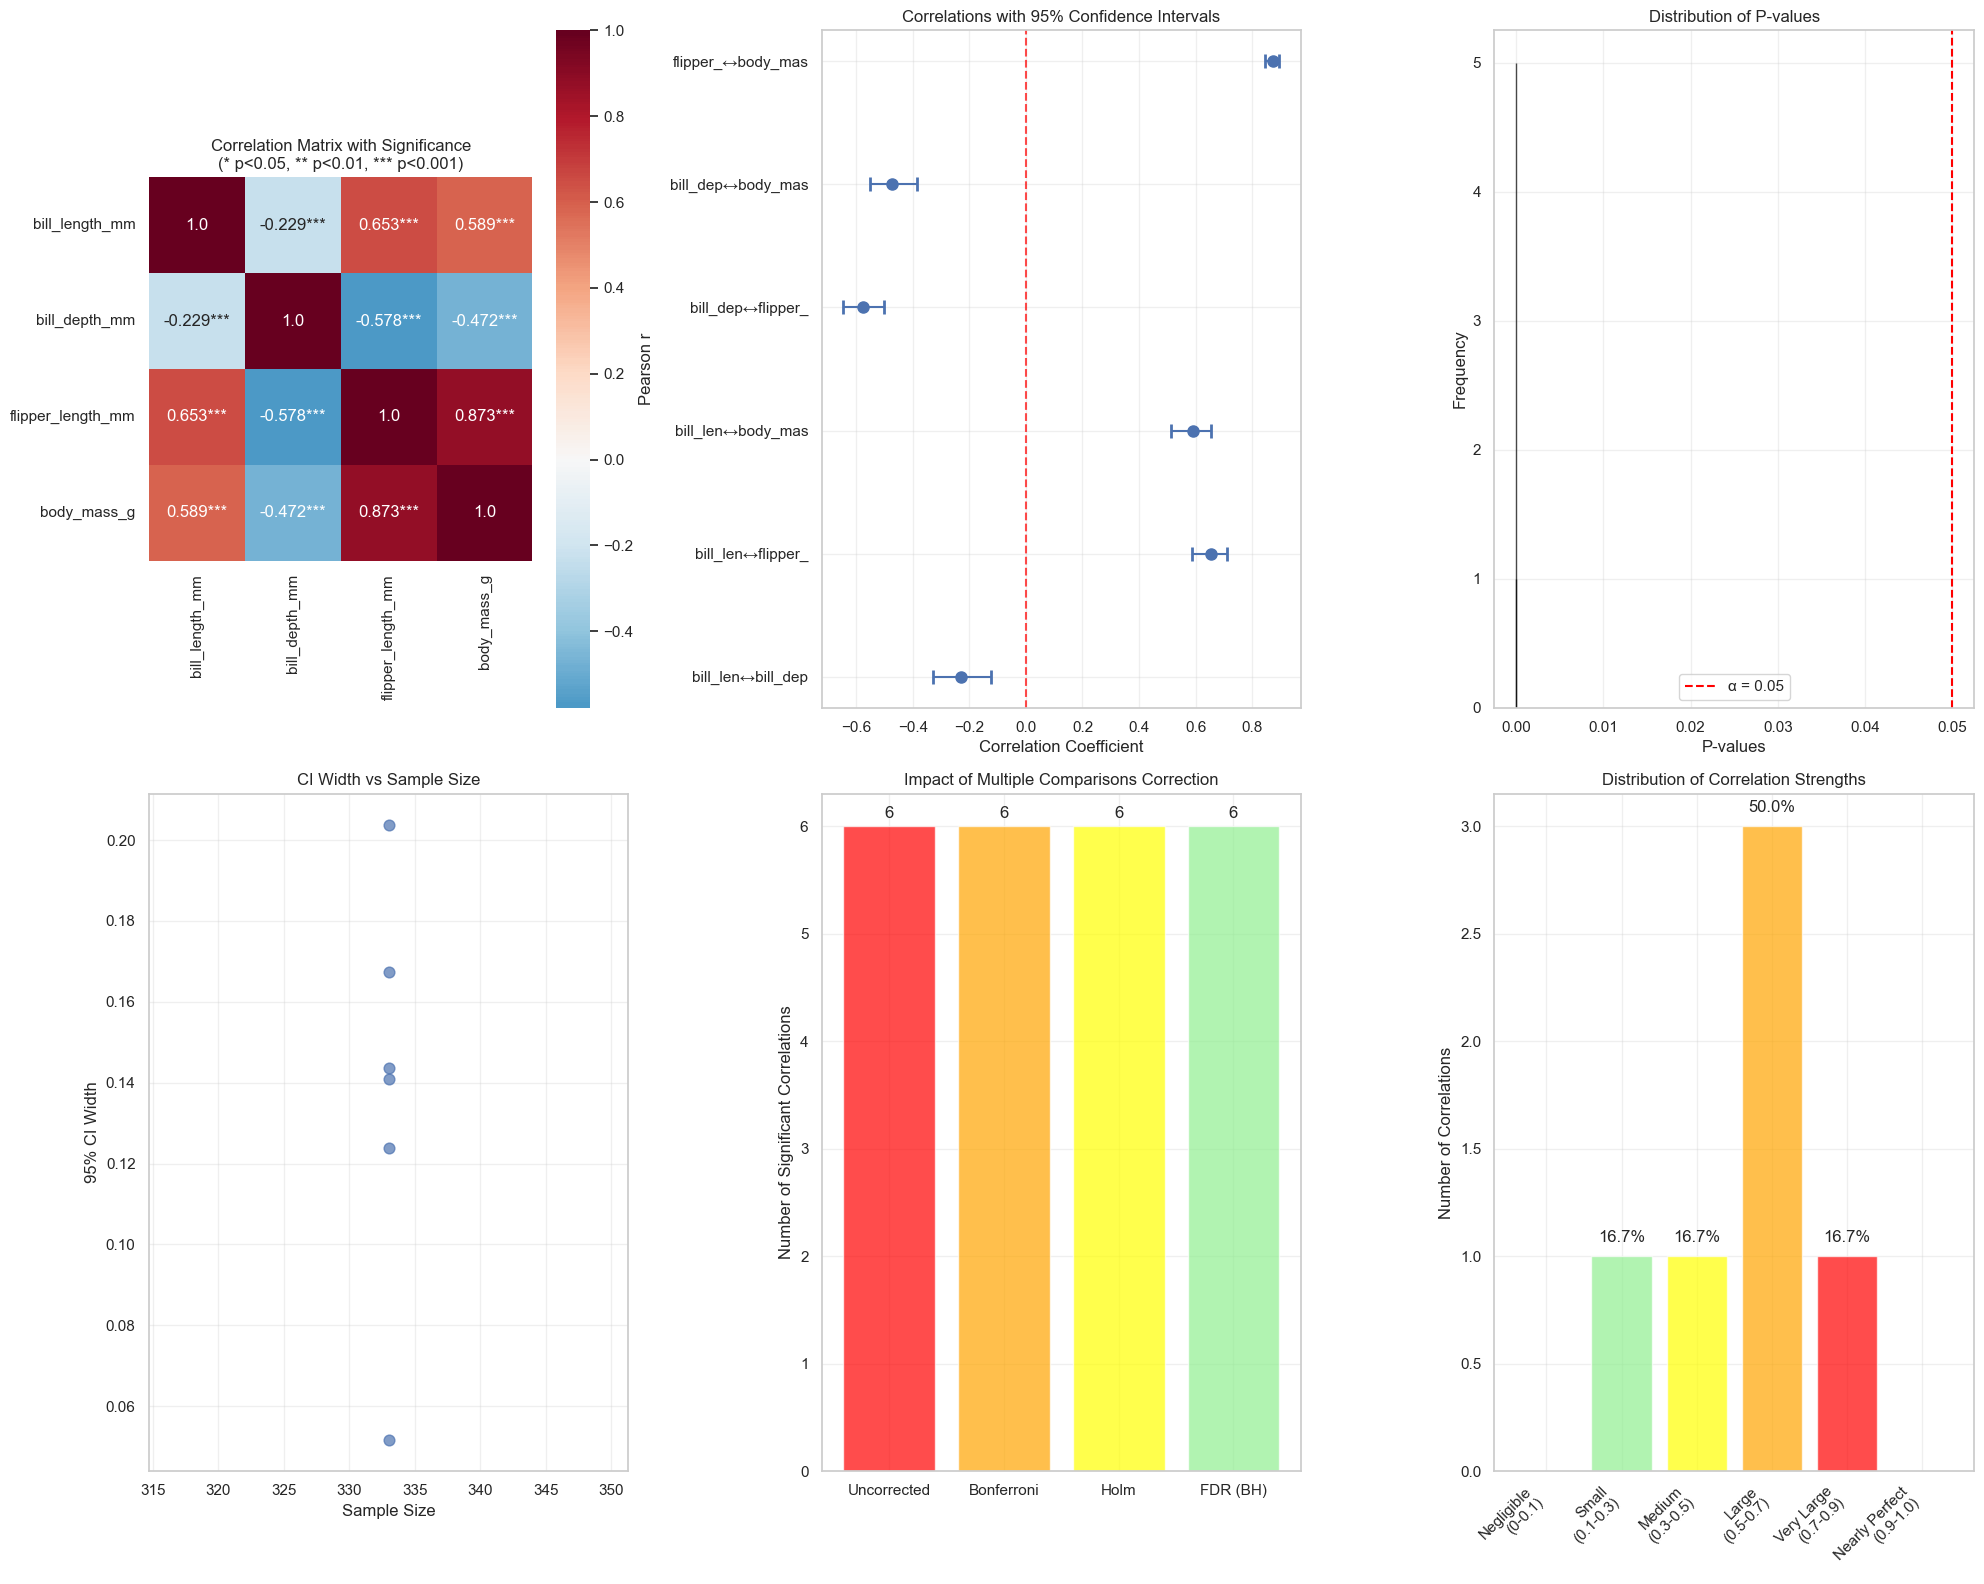


 Step 3: Hierarchical clustering of correlation matrix

HIERARCHICAL CLUSTERING OF CORRELATION MATRIX


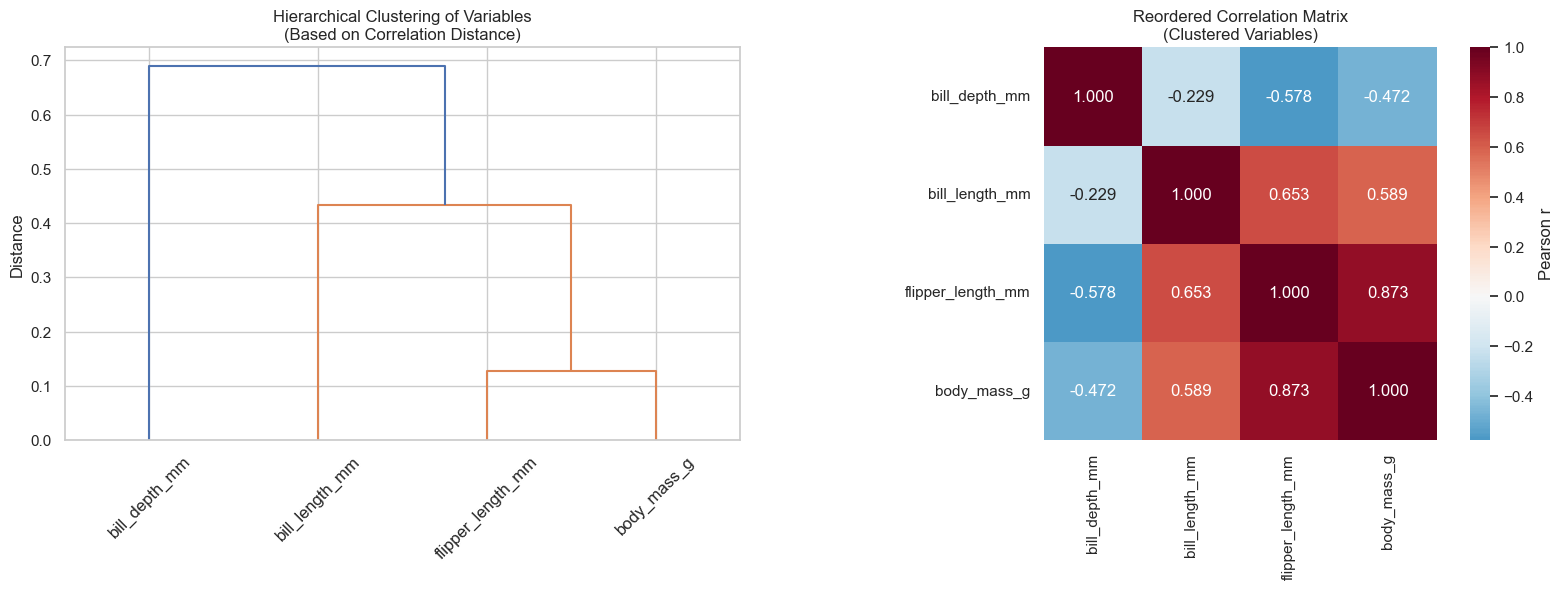

Variable clustering at different cut levels:
---------------------------------------------

2 clusters:
  Cluster 1: ['bill_length_mm', 'flipper_length_mm', 'body_mass_g']
  Cluster 2: ['bill_depth_mm']

3 clusters:
  Cluster 1: ['flipper_length_mm', 'body_mass_g']
  Cluster 2: ['bill_length_mm']
  Cluster 3: ['bill_depth_mm']

4 clusters:
  Cluster 1: ['bill_length_mm']
  Cluster 2: ['bill_depth_mm']
  Cluster 3: ['flipper_length_mm']
  Cluster 4: ['body_mass_g']

 Step 4: Bootstrap confidence intervals demonstration

BOOTSTRAP CONFIDENCE INTERVALS: flipper_length_mm vs body_mass_g
Original sample size: 333
Bootstrap samples: 1000
Confidence level: 95%

Results:
----------
Original correlation: 0.8730
Bootstrap mean: 0.8729
Bootstrap bias: -0.0001
Bootstrap std: 0.0119

Confidence Intervals:
----------------------
Bootstrap CI:   [0.8471, 0.8945]
Fisher's Z CI:  [0.8448, 0.8964]


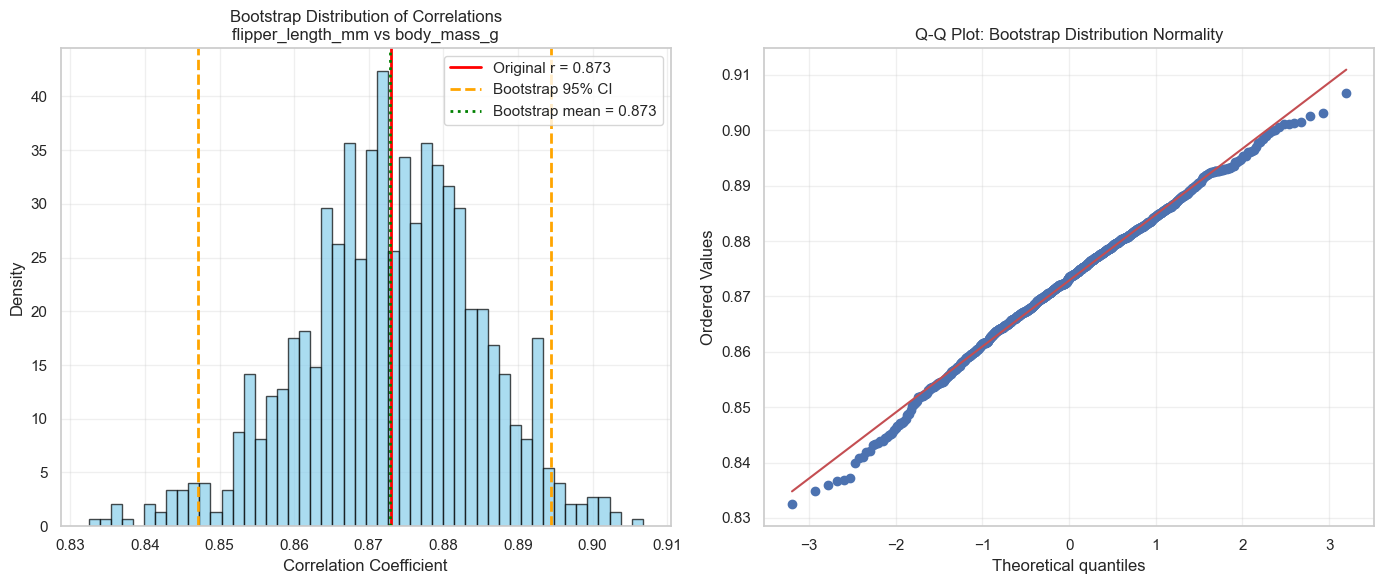


 Step 5: Power analysis for correlation studies

POWER ANALYSIS FOR CORRELATION STUDIES
Cohen's guidelines for correlation effect sizes:
Small effect:    |r| = 0.10
Medium effect:   |r| = 0.30
Large effect:    |r| = 0.50

Power analysis parameters:
Alpha level: 0.05
Desired power: 0.8

Sample size requirements for 80% power:
---------------------------------------------
r = 0.1: n =  783
r = 0.2: n =  194
r = 0.3: n =   85
r = 0.4: n =   47
r = 0.5: n =   30


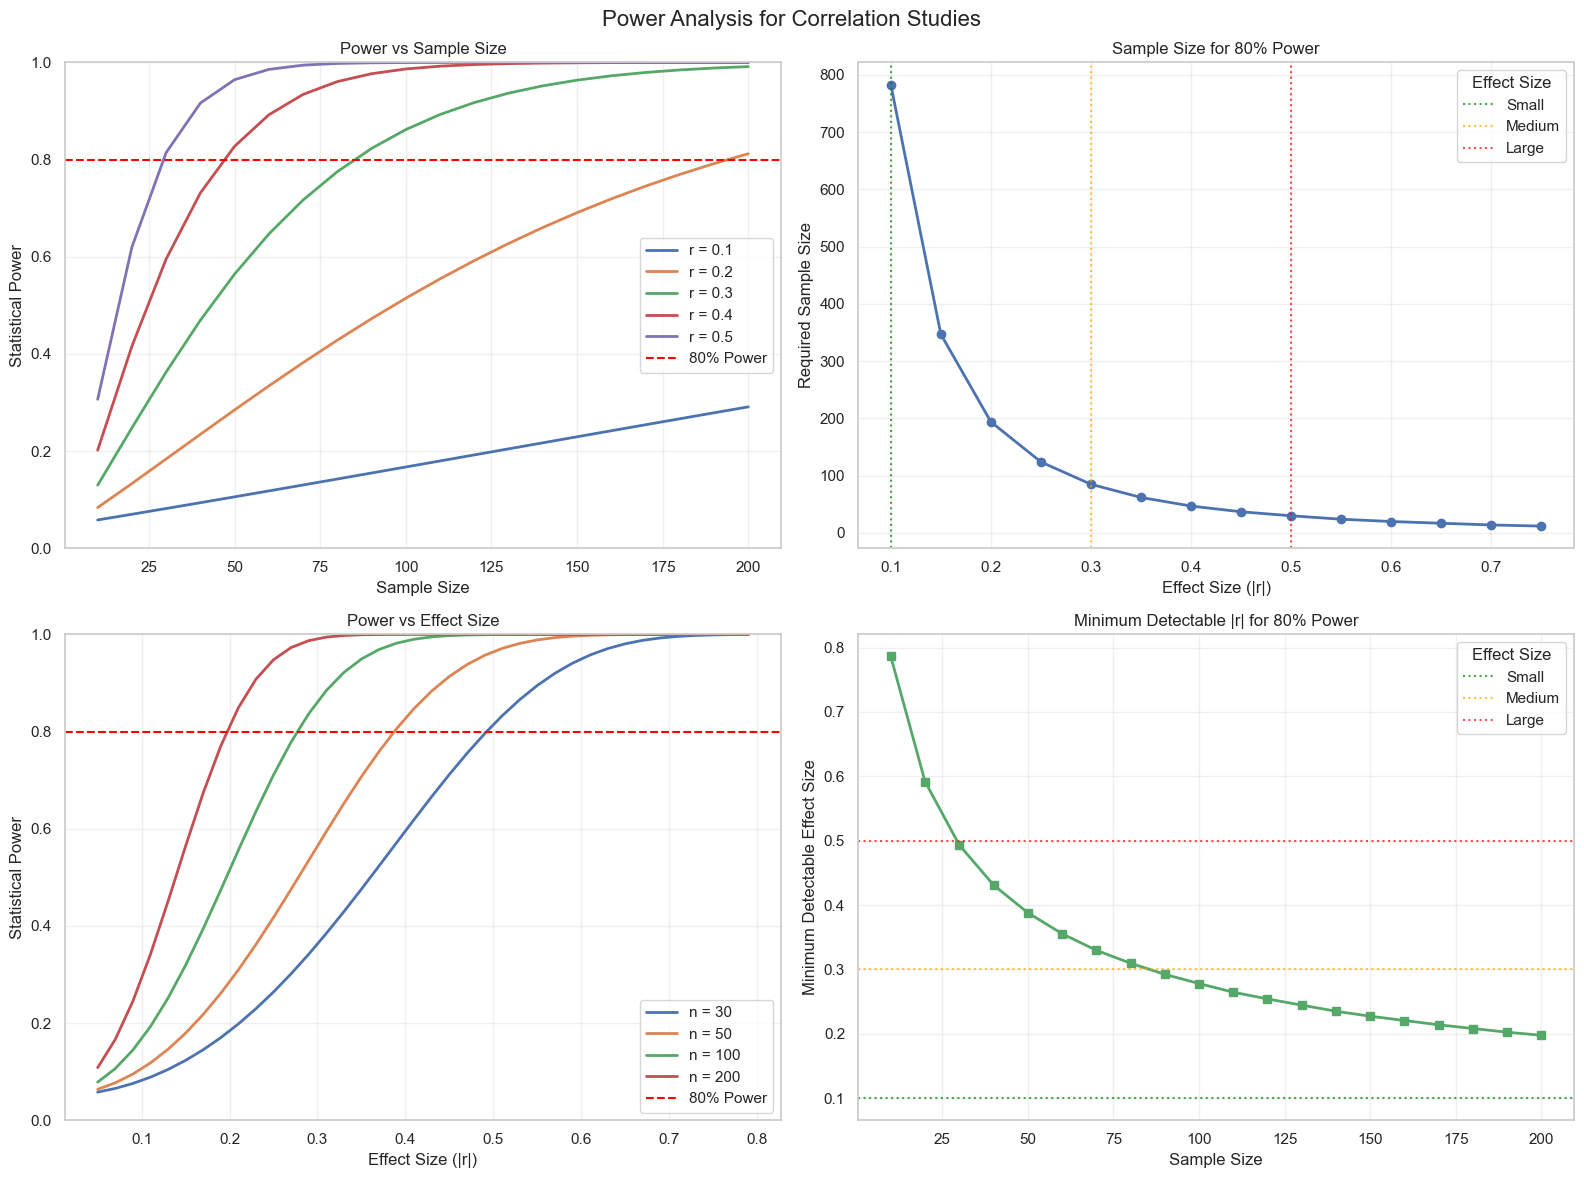


 Step 6: Practical correlation reporting guide

PRACTICAL GUIDE FOR REPORTING CORRELATIONS
Essential elements for reporting correlations:
---------------------------------------------
1. Correlation coefficient type (Pearson/Spearman)
2. Sample size and degrees of freedom
3. Confidence intervals
4. Statistical significance
5. Effect size interpretation
6. Multiple comparisons correction (if applicable)

Example reporting formats:
---------------------------

Example 1:
Standard format:
  'There was a small negative correlation between
   bill length mm and bill depth mm, r(331) = -0.229,
   95% CI [-0.328, -0.124], p < .001.'
APA format:
  'Bill Length Mm and bill depth mm were significantly correlated,
   r = -0.23, p < .001, 95% CI [-0.33, -0.12].'

Example 2:
Standard format:
  'There was a large positive correlation between
   bill length mm and flipper length mm, r(331) = 0.653,
   95% CI [0.587, 0.711], p < .001.'
APA format:
  'Bill Length Mm and flipper length mm were signific

In [15]:
# Calculating confidence intervals to pearson r using Fisher's Z-transform
# 1. Convert the correlation r to Fisher’s Z-space where it’s approximately normally distributed.
# once normally distributed, we can use standard techniques for confidence intervals.
# 2. Calculate the standard error (SE) in Z-space using the sample size n.
# 3. Build a confidence interval in Z-space using a critical value from the normal distribution.
# 4. Convert the interval back to the correlation scale using the inverse Fisher transformation.

def fishers_z_transform(r):
    """
    Apply Fisher's Z transformation to correlation coefficient.
    Formula: Z = 0.5 × ln((1 + r) / (1 - r))

    """
    # Handle edge cases where r is exactly ±1
    r = np.clip(r, -0.9999, 0.9999)
    return 0.5 * np.log((1 + r) / (1 - r))

def inverse_fishers_z(z):
    """
    Convert Fisher's Z back to correlation coefficient.

    """
    return (np.exp(2 * z) - 1) / (np.exp(2 * z) + 1)

def correlation_confidence_interval(r, n, confidence_level=0.95):
    """
    Calculate confidence interval for a correlation coefficient using Fisher's Z transformation.

    """
    # Fisher's Z transformation
    z = fishers_z_transform(r)

    # Standard error of Z (1 over sq. root n-3)
    se_z = 1 / np.sqrt(n - 3)

    # Critical value for confidence interval
    alpha = 1 - confidence_level
    z_critical = stats.norm.ppf(1 - alpha/2)

    # Confidence interval for Z
    z_lower = z - z_critical * se_z
    z_upper = z + z_critical * se_z

    # Transform back to correlation scale
    r_lower = inverse_fishers_z(z_lower)
    r_upper = inverse_fishers_z(z_upper)

    return r_lower, r_upper, z, se_z


#Correlation matrix analysis
# 1. Calculate Pairwise Pearson Correlations: For each pair of continuous variables,
# compute the correlation coefficient and its p-value, along with the sample size used.

# 2. Build Confidence Intervals for Each Correlation: Using Fisher's Z transformation,
# estimate confidence intervals (default 95%) for the correlation values, helping you gauge the uncertainty.
# It's like calculating 3 correlation matrices, one we had before and two more - lower and upper uncertainties

# 3. Store and Display Results: Organize the raw correlations, p-values, CI bounds,
# and sample sizes into matrices and also prints detailed stats for each unique pair.

# 4. Apply Multiple Comparisons Correction: To control the false discovery rate across
# all pairwise tests, adjust p-values using methods like Bonferroni, Holm, and
# FDR (Benjamini-Hochberg/Yekutieli), and report how many remain statistically significant.

def comprehensive_correlation_matrix_analysis(data, continuous_vars, confidence_level=0.95):
    """
    Perform comprehensive correlation matrix analysis with confidence intervals and significance testing.
    """
    print(f"\n" + "=" * 70)
    print("COMPREHENSIVE CORRELATION MATRIX ANALYSIS")
    print("=" * 70)

    # Calculate correlation matrix with all pairwise statistics
    n_vars = len(continuous_vars)
    results_matrix = {}

    # Initialize result storage
    correlations = np.zeros((n_vars, n_vars))
    p_values = np.zeros((n_vars, n_vars))
    lower_bounds = np.zeros((n_vars, n_vars))
    upper_bounds = np.zeros((n_vars, n_vars))
    sample_sizes = np.zeros((n_vars, n_vars))

    print(f"Calculating correlations with {confidence_level*100:.0f}% confidence intervals:")
    print("-" * 60)

    detailed_results = []

    for i, var1 in enumerate(continuous_vars):
        for j, var2 in enumerate(continuous_vars):
            if i == j:
                # Diagonal elements
                correlations[i, j] = 1.0
                p_values[i, j] = 0.0
                lower_bounds[i, j] = 1.0
                upper_bounds[i, j] = 1.0
                sample_sizes[i, j] = len(data[var1].dropna())
            else:
                # Off-diagonal elements
                clean_data = data[[var1, var2]].dropna()
                x = clean_data[var1]
                y = clean_data[var2]
                n = len(clean_data)

                # Calculate correlation and significance
                r, p = pearsonr(x, y)

                # Calculate confidence interval
                r_lower, r_upper, fisher_z, se_z = correlation_confidence_interval(r, n, confidence_level)

                # Store results
                correlations[i, j] = r
                p_values[i, j] = p
                lower_bounds[i, j] = r_lower
                upper_bounds[i, j] = r_upper
                sample_sizes[i, j] = n

                # Store detailed results for unique pairs
                if i < j:
                    detailed_results.append({
                        'var1': var1,
                        'var2': var2,
                        'correlation': r,
                        'p_value': p,
                        'ci_lower': r_lower,
                        'ci_upper': r_upper,
                        'fisher_z': fisher_z,
                        'se_z': se_z,
                        'sample_size': n,
                        'ci_width': r_upper - r_lower
                    })

                    print(f"{var1} ↔ {var2}:")
                    print(f"  r = {r:>7.3f} [{r_lower:>6.3f}, {r_upper:>6.3f}], p = {p:>7.4f}, n = {n:>3}")

    # Create DataFrames for easy manipulation
    corr_df = pd.DataFrame(correlations, index=continuous_vars, columns=continuous_vars)
    p_values_df = pd.DataFrame(p_values, index=continuous_vars, columns=continuous_vars)

    print(f"\nCorrelation Matrix:")
    print("-" * 20)
    print(corr_df.round(3))

    # Multiple comparisons correction
    print(f"\nMultiple Comparisons Correction:")
    print("-" * 35)

    # Extract p-values for unique pairs (upper triangle)
    unique_p_values = []
    for result in detailed_results:
        unique_p_values.append(result['p_value'])

    # Apply different correction methods
    # We use: statsmodels.stats.multitest.multipletests where these can be inputs
    # Bonferroni correction works by dividing your desired significance level (like 0.05)
    # by the number of comparisons you're making. So if you're testing 6 pairs, the new threshold
    # becomes 0.05 ÷ 6 = 0.0083 — meaning each individual p-value must be less than 0.0083 to be considered significant.
    corrections = {
        'Bonferroni': 'bonferroni',
        'Holm': 'holm',
        'FDR (Benjamini-Hochberg)': 'fdr_bh',
        'FDR (Benjamini-Yekutieli)': 'fdr_by'
    }

    for method_name, method_code in corrections.items():
        rejected, p_adjusted, alpha_sidak, alpha_bonf = multipletests(unique_p_values, method=method_code)

        # Update detailed results
        for i, result in enumerate(detailed_results):
            result[f'p_adjusted_{method_code}'] = p_adjusted[i]
            result[f'significant_{method_code}'] = rejected[i]

        significant_count = sum(rejected)
        print(f"{method_name:<25}: {significant_count:>2} significant out of {len(unique_p_values)}")

    return {
        'correlation_matrix': corr_df,
        'p_values_matrix': p_values_df,
        'lower_bounds': lower_bounds,
        'upper_bounds': upper_bounds,
        'detailed_results': detailed_results,
        'sample_sizes': sample_sizes
    }

def create_advanced_correlation_visualizations(correlation_analysis, continuous_vars):
    """
    Create advanced visualizations for correlation analysis.
    """
    print(f"\n" + "=" * 70)
    print("ADVANCED CORRELATION VISUALIZATIONS")
    print("=" * 70)

    corr_matrix = correlation_analysis['correlation_matrix']
    p_values_matrix = correlation_analysis['p_values_matrix']
    detailed_results = correlation_analysis['detailed_results']

    # Create comprehensive visualization
    fig = plt.figure(figsize=(20, 16))

    # 1. Enhanced correlation heatmap with significance stars
    ax1 = plt.subplot(2, 3, 1)

    # Create annotation matrix with significance stars
    annotations = corr_matrix.round(3).astype(str)

    for i in range(len(continuous_vars)):
        for j in range(len(continuous_vars)):
            if i != j:
                p_val = p_values_matrix.iloc[i, j]
                corr_val = corr_matrix.iloc[i, j]

                # Add significance stars
                if p_val < 0.001:
                    star = "***"
                elif p_val < 0.01:
                    star = "**"
                elif p_val < 0.05:
                    star = "*"
                else:
                    star = ""

                annotations.iloc[i, j] = f"{corr_val:.3f}{star}"

    # Create mask for upper triangle
    # mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

    sns.heatmap(corr_matrix,
                #mask=mask,
                annot=annotations, fmt='', cmap='RdBu_r', center=0,
                square=True, ax=ax1, cbar_kws={'label': 'Pearson r'})
    ax1.set_title('Correlation Matrix with Significance\n(* p<0.05, ** p<0.01, *** p<0.001)')

    # 2. Confidence interval visualization
    ax2 = plt.subplot(2, 3, 2)

    # Extract data for plotting
    correlations = [result['correlation'] for result in detailed_results]
    ci_lowers = [result['ci_lower'] for result in detailed_results]
    ci_uppers = [result['ci_upper'] for result in detailed_results]
    pair_names = [f"{result['var1'][:8]}↔{result['var2'][:8]}" for result in detailed_results]

    y_pos = np.arange(len(pair_names))

    # Create horizontal error bars
    ax2.errorbar(correlations, y_pos, xerr=[np.array(correlations) - np.array(ci_lowers),
                                           np.array(ci_uppers) - np.array(correlations)],
                fmt='o', capsize=5, capthick=2, markersize=8)

    ax2.axvline(x=0, color='red', linestyle='--', alpha=0.7)
    ax2.set_yticks(y_pos)
    ax2.set_yticklabels(pair_names)
    ax2.set_xlabel('Correlation Coefficient')
    ax2.set_title('Correlations with 95% Confidence Intervals')
    ax2.grid(True, alpha=0.3)

    # 3. P-value distribution
    ax3 = plt.subplot(2, 3, 3)

    p_vals = [result['p_value'] for result in detailed_results]
    ax3.hist(p_vals, bins=10, alpha=0.7, color='skyblue', edgecolor='black')
    ax3.axvline(x=0.05, color='red', linestyle='--', label='α = 0.05')
    ax3.set_xlabel('P-values')
    ax3.set_ylabel('Frequency')
    ax3.set_title('Distribution of P-values')
    ax3.legend()
    ax3.grid(True, alpha=0.3)

    # 4. Confidence interval widths
    ax4 = plt.subplot(2, 3, 4)

    ci_widths = [result['ci_upper'] - result['ci_lower'] for result in detailed_results]
    sample_sizes = [result['sample_size'] for result in detailed_results]

    ax4.scatter(sample_sizes, ci_widths, alpha=0.7, s=60)
    ax4.set_xlabel('Sample Size')
    ax4.set_ylabel('95% CI Width')
    ax4.set_title('CI Width vs Sample Size')
    ax4.grid(True, alpha=0.3)

    # Add trendline
    z = np.polyfit(sample_sizes, ci_widths, 1)
    p = np.poly1d(z)
    ax4.plot(sample_sizes, p(sample_sizes), "r--", alpha=0.8)

    # 5. Multiple comparisons impact
    ax5 = plt.subplot(2, 3, 5)

    methods = ['Uncorrected', 'Bonferroni', 'Holm', 'FDR (BH)']
    significant_counts = []

    # Uncorrected
    uncorrected_sig = sum(1 for result in detailed_results if result['p_value'] < 0.05)
    significant_counts.append(uncorrected_sig)

    # Corrected methods
    for method in ['bonferroni', 'holm', 'fdr_bh']:
        method_sig = sum(1 for result in detailed_results if result[f'significant_{method}'])
        significant_counts.append(method_sig)

    bars = ax5.bar(methods, significant_counts, alpha=0.7,
                   color=['red', 'orange', 'yellow', 'lightgreen'])
    ax5.set_ylabel('Number of Significant Correlations')
    ax5.set_title('Impact of Multiple Comparisons Correction')
    ax5.grid(True, alpha=0.3)

    # Add value labels on bars
    for bar, count in zip(bars, significant_counts):
        height = bar.get_height()
        ax5.text(bar.get_x() + bar.get_width()/2., height + 0.05,
                f'{count}', ha='center', va='bottom')

    # 6. Correlation strength distribution
    ax6 = plt.subplot(2, 3, 6)

    abs_correlations = [abs(result['correlation']) for result in detailed_results]

    # Create bins for correlation strength
    bins = [0, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0]
    labels = ['Negligible\n(0-0.1)', 'Small\n(0.1-0.3)', 'Medium\n(0.3-0.5)',
              'Large\n(0.5-0.7)', 'Very Large\n(0.7-0.9)', 'Nearly Perfect\n(0.9-1.0)']

    counts, _ = np.histogram(abs_correlations, bins=bins)

    bars = ax6.bar(range(len(counts)), counts, alpha=0.7,
                   color=['lightblue', 'lightgreen', 'yellow', 'orange', 'red', 'darkred'])
    ax6.set_xticks(range(len(counts)))
    ax6.set_xticklabels(labels, rotation=45, ha='right')
    ax6.set_ylabel('Number of Correlations')
    ax6.set_title('Distribution of Correlation Strengths')
    ax6.grid(True, alpha=0.3)

    # Add percentage labels
    total_corrs = len(abs_correlations)
    for i, (bar, count) in enumerate(zip(bars, counts)):
        if count > 0:
            percentage = (count / total_corrs) * 100
            ax6.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.05,
                    f'{percentage:.1f}%', ha='center', va='bottom')

    plt.tight_layout()
    plt.show()


# Hierarchical Clustering of Correlation Matrix
# 1. Convert Correlations to Distances: Transform the correlation matrix into a distance matrix using the formula:
# Distance = 1 −∣correlation∣ - This way, variables that are highly correlated (positive or negative) are considered “close.”

# 2. Perform Hierarchical Clustering: Apply hierarchical clustering (Ward's method) to group similar variables based on their
# pairwise distances — identifying natural clusters of correlated variables.

# 3. Visualize the Results: Plot a dendrogram showing how variables cluster hierarchically.
# Reorder and plot the correlation matrix based on clustering so related variables are grouped visually in blocks.

# 4. Print Cluster Groupings at Multiple Levels: Show which variables fall into 2, 3, or 4 clusters,
# helping us interpret the structure at different granularity levels.

def hierarchical_clustering_correlations(correlation_matrix, continuous_vars):
    """
    Perform hierarchical clustering on correlation matrix to identify variable groups.
    """
    print(f"\n" + "=" * 70)
    print("HIERARCHICAL CLUSTERING OF CORRELATION MATRIX")
    print("=" * 70)

    # Convert correlation matrix to distance matrix
    # Distance = 1 - |correlation|
    distance_matrix = 1 - np.abs(correlation_matrix.values)

    # Ensure distance matrix is symmetric and has zero diagonal (distance to itself is obviously zero)
    np.fill_diagonal(distance_matrix, 0)
    distance_matrix = (distance_matrix + distance_matrix.T) / 2

    # Convert to condensed form for scipy
    condensed_distances = squareform(distance_matrix) # 2D to 1D. Linkage function expects distances in 1D format—not a full 2D matrix

    # Perform hierarchical clustering
    linkage_matrix = linkage(condensed_distances, method='ward') # Performs hierarchical agglomerative clustering using the Ward method.

    # Create dendrogram
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

    # Plot dendrogram
    dendrogram_result = dendrogram(linkage_matrix, labels=continuous_vars,
                                  orientation='top', ax=ax1)
    ax1.set_title('Hierarchical Clustering of Variables\n(Based on Correlation Distance)')
    ax1.set_ylabel('Distance')
    ax1.tick_params(axis='x', rotation=45)

    # Reorder correlation matrix based on clustering
    cluster_order = dendrogram_result['leaves']
    reordered_vars = [continuous_vars[i] for i in cluster_order]
    reordered_corr = correlation_matrix.loc[reordered_vars, reordered_vars]

    # Plot reordered correlation matrix
    # mask = np.triu(np.ones_like(reordered_corr, dtype=bool))
    sns.heatmap(reordered_corr,
                #mask=mask,
                annot=True, cmap='RdBu_r', center=0,
                square=True, fmt='.3f', ax=ax2,
                cbar_kws={'label': 'Pearson r'})
    ax2.set_title('Reordered Correlation Matrix\n(Clustered Variables)')

    plt.tight_layout()
    plt.show()

    # Extract clusters at different levels
    print(f"Variable clustering at different cut levels:")
    print("-" * 45)

    for n_clusters in [2, 3, 4]:
        cluster_labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')

        print(f"\n{n_clusters} clusters:")
        for cluster_id in range(1, n_clusters + 1):
            cluster_vars = [continuous_vars[i] for i, label in enumerate(cluster_labels) if label == cluster_id]
            print(f"  Cluster {cluster_id}: {cluster_vars}")

    return {
        'linkage_matrix': linkage_matrix,
        'distance_matrix': distance_matrix,
        'cluster_order': cluster_order,
        'reordered_correlation_matrix': reordered_corr
    }


# Bootstrap Confidence Intervals for Correlation
# 1. Calculate the Original Correlation: Compute the Pearson correlation and p-value
# between two variables using the original dataset (after dropping missing values).

# 2. Generate a Bootstrap Distribution: Repeatedly resample the data with replacement
# to create many new datasets, compute correlation for each, and build a distribution of correlation values.

# 3. Compute Bootstrap Confidence Intervals: Use the percentile method (e.g., 2.5th and 97.5th percentiles for 95% CI)
# to estimate a confidence interval from the bootstrap distribution.
# Also compare this to the Fisher’s Z-based confidence interval.

# 4. Visualize and Report Key Statistics: Plot the bootstrap distribution, highlight key values like the original correlation,
# bootstrap mean, and confidence bounds, and shows a Q-Q plot to assess normality of the bootstrap distribution.
# Also report bias and standard deviation of the bootstrap estimate.

def bootstrap_correlation_confidence_intervals(data, var1, var2, n_bootstrap=1000, confidence_level=0.95):
    """
    Calculate bootstrap confidence intervals for correlation coefficient.

    """
    print(f"\n" + "=" * 60)
    print(f"BOOTSTRAP CONFIDENCE INTERVALS: {var1} vs {var2}")
    print("=" * 60)

    # Get clean data
    clean_data = data[[var1, var2]].dropna()
    x = clean_data[var1].values
    y = clean_data[var2].values
    n = len(clean_data)

    print(f"Original sample size: {n}")
    print(f"Bootstrap samples: {n_bootstrap}")
    print(f"Confidence level: {confidence_level*100:.0f}%")

    # Calculate original correlation
    original_r, original_p = pearsonr(x, y)

    # Bootstrap sampling
    bootstrap_correlations = []

    np.random.seed(42)  # For reproducibility

    for i in range(n_bootstrap):
        # Resample with replacement
        indices = np.random.choice(n, size=n, replace=True)
        x_boot = x[indices]
        y_boot = y[indices]

        # Calculate correlation for bootstrap sample
        r_boot, _ = pearsonr(x_boot, y_boot)
        bootstrap_correlations.append(r_boot)

    bootstrap_correlations = np.array(bootstrap_correlations)

    # Calculate confidence intervals using percentile method
    alpha = 1 - confidence_level
    lower_percentile = (alpha / 2) * 100
    upper_percentile = (1 - alpha / 2) * 100

    ci_lower_boot = np.percentile(bootstrap_correlations, lower_percentile)
    ci_upper_boot = np.percentile(bootstrap_correlations, upper_percentile)

    # Calculate Fisher's Z confidence interval for comparison
    ci_lower_fisher, ci_upper_fisher, _, _ = correlation_confidence_interval(original_r, n, confidence_level)

    # Statistics
    boot_mean = np.mean(bootstrap_correlations)
    boot_std = np.std(bootstrap_correlations)
    boot_bias = boot_mean - original_r

    print(f"\nResults:")
    print("-" * 10)
    print(f"Original correlation: {original_r:.4f}")
    print(f"Bootstrap mean: {boot_mean:.4f}")
    print(f"Bootstrap bias: {boot_bias:.4f}")
    print(f"Bootstrap std: {boot_std:.4f}")

    print(f"\nConfidence Intervals:")
    print("-" * 22)
    print(f"Bootstrap CI:   [{ci_lower_boot:.4f}, {ci_upper_boot:.4f}]")
    print(f"Fisher's Z CI:  [{ci_lower_fisher:.4f}, {ci_upper_fisher:.4f}]")

    # Visualization
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

    # Plot 1: Bootstrap distribution
    ax1.hist(bootstrap_correlations, bins=50, alpha=0.7, density=True,
            color='skyblue', edgecolor='black')

    # Add lines for original correlation and confidence interval
    ax1.axvline(original_r, color='red', linestyle='-', linewidth=2, label=f'Original r = {original_r:.3f}')
    ax1.axvline(ci_lower_boot, color='orange', linestyle='--', linewidth=2)
    ax1.axvline(ci_upper_boot, color='orange', linestyle='--', linewidth=2,
               label=f'Bootstrap 95% CI')
    ax1.axvline(boot_mean, color='green', linestyle=':', linewidth=2, label=f'Bootstrap mean = {boot_mean:.3f}')

    ax1.set_xlabel('Correlation Coefficient')
    ax1.set_ylabel('Density')
    ax1.set_title(f'Bootstrap Distribution of Correlations\n{var1} vs {var2}')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # Plot 2: Q-Q plot to check normality of bootstrap distribution
    stats.probplot(bootstrap_correlations, dist="norm", plot=ax2)
    ax2.set_title('Q-Q Plot: Bootstrap Distribution Normality')
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    return {
        'original_correlation': original_r,
        'original_p_value': original_p,
        'bootstrap_correlations': bootstrap_correlations,
        'bootstrap_mean': boot_mean,
        'bootstrap_std': boot_std,
        'bootstrap_bias': boot_bias,
        'ci_lower_bootstrap': ci_lower_boot,
        'ci_upper_bootstrap': ci_upper_boot,
        'ci_lower_fisher': ci_lower_fisher,
        'ci_upper_fisher': ci_upper_fisher
    }

# Power Analysis for Correlation Studies

# 1. Estimate Required Sample Sizes for Desired Power: For a given target power (e.g. 80%), calculate how many samples
# we need to detect various correlation strengths (e.g., small = 0.1, medium = 0.3, large = 0.5) using Fisher’s Z transformation.

# 2. Compute Statistical Power Across Sample Sizes and Effect Sizes: Calculate and plot how power increases as
# sample size increases for fixed correlation levels — helping us see when our study becomes adequately powered.

# 3. Visualize Critical Trade-offs
# Generate four key plots:
#   i. Power vs Sample Size for various effect sizes
#   ii. Sample Size vs Effect Size for achieving target power
#   iii. Power vs Effect Size for different sample sizes
#   iv. Minimum Detectable Correlation for a range of sample sizes at fixed power

# 4. Highlight Cohen’s Guidelines: Overlay visual benchmarks (small, medium, large effects) to help us interpret results
# using widely accepted effect size categories.


def power_analysis_correlation(effect_sizes=None, sample_sizes=None, alpha=0.05, power=0.8):
    """
    Perform power analysis for correlation studies.

    """
    print(f"\n" + "=" * 70)
    print("POWER ANALYSIS FOR CORRELATION STUDIES")
    print("=" * 70)

    if effect_sizes is None:
        effect_sizes = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

    if sample_sizes is None:
        sample_sizes = list(range(10, 201, 10))

    # Cohen's guidelines for effect sizes
    print(f"Cohen's guidelines for correlation effect sizes:")
    print(f"Small effect:    |r| = 0.10")
    print(f"Medium effect:   |r| = 0.30")
    print(f"Large effect:    |r| = 0.50")

    print(f"\nPower analysis parameters:")
    print(f"Alpha level: {alpha}")
    print(f"Desired power: {power}")

    # Function to calculate power for given r and n
    def calculate_power(r, n, alpha=0.05):
        if n <= 3:
            return 0.0

        # Calculate non-centrality parameter
        z_r = fishers_z_transform(r)
        se_z = 1 / np.sqrt(n - 3)

        # Critical value
        z_critical = stats.norm.ppf(1 - alpha/2)

        # Power calculation using non-central distribution
        # This is an approximation
        delta = abs(z_r) / se_z
        power = 1 - stats.norm.cdf(z_critical - delta) + stats.norm.cdf(-z_critical - delta)

        return min(power, 1.0)

    # Function to calculate required sample size
    def calculate_required_n(r, power=0.8, alpha=0.05):
        if abs(r) < 0.01:
            return float('inf')

        z_alpha = stats.norm.ppf(1 - alpha/2)
        z_beta = stats.norm.ppf(power)

        # Fisher's Z transformation
        z_r = fishers_z_transform(r)

        # Required sample size formula
        n_required = ((z_alpha + z_beta) / z_r)**2 + 3

        return max(4, int(np.ceil(n_required)))

    # Calculate power curves
    print(f"\nSample size requirements for {power*100:.0f}% power:")
    print("-" * 45)

    required_ns = []
    for r in [0.1, 0.2, 0.3, 0.4, 0.5]:
        req_n = calculate_required_n(r, power, alpha)
        required_ns.append(req_n)
        print(f"r = {r:.1f}: n = {req_n:>4}")

    # Create power analysis visualizations
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle('Power Analysis for Correlation Studies', fontsize=16)

    # Plot 1: Power vs Sample Size for different effect sizes
    for r in [0.1, 0.2, 0.3, 0.4, 0.5]:
        powers = [calculate_power(r, n, alpha) for n in sample_sizes]
        ax1.plot(sample_sizes, powers, label=f'r = {r:.1f}', linewidth=2)

    ax1.axhline(y=power, color='red', linestyle='--', label=f'{power*100:.0f}% Power')
    ax1.set_xlabel('Sample Size')
    ax1.set_ylabel('Statistical Power')
    ax1.set_title('Power vs Sample Size')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    ax1.set_ylim(0, 1)

    # Plot 2: Required Sample Size vs Effect Size
    effect_range = np.arange(0.1, 0.8, 0.05)
    required_sample_sizes = [calculate_required_n(r, power, alpha) for r in effect_range]

    # Cap extremely large sample sizes for visualization
    required_sample_sizes = [min(n, 1000) for n in required_sample_sizes]

    ax2.plot(effect_range, required_sample_sizes, 'b-', linewidth=2, marker='o')
    ax2.set_xlabel('Effect Size (|r|)')
    ax2.set_ylabel('Required Sample Size')
    ax2.set_title(f'Sample Size for {power*100:.0f}% Power')
    ax2.grid(True, alpha=0.3)

    # Add Cohen's guidelines
    ax2.axvline(x=0.1, color='green', linestyle=':', alpha=0.7, label='Small')
    ax2.axvline(x=0.3, color='orange', linestyle=':', alpha=0.7, label='Medium')
    ax2.axvline(x=0.5, color='red', linestyle=':', alpha=0.7, label='Large')
    ax2.legend(title='Effect Size')

    # Plot 3: Power vs Effect Size for different sample sizes
    sample_size_examples = [30, 50, 100, 200]
    effect_range_fine = np.arange(0.05, 0.8, 0.02)

    for n in sample_size_examples:
        powers = [calculate_power(r, n, alpha) for r in effect_range_fine]
        ax3.plot(effect_range_fine, powers, label=f'n = {n}', linewidth=2)

    ax3.axhline(y=power, color='red', linestyle='--', label=f'{power*100:.0f}% Power')
    ax3.set_xlabel('Effect Size (|r|)')
    ax3.set_ylabel('Statistical Power')
    ax3.set_title('Power vs Effect Size')
    ax3.legend()
    ax3.grid(True, alpha=0.3)
    ax3.set_ylim(0, 1)

    # Plot 4: Minimum detectable effect size
    min_detectable_r = []
    for n in sample_sizes:
        # Binary search for minimum r that achieves desired power
        low, high = 0.01, 0.99
        while high - low > 0.001:
            mid = (low + high) / 2
            if calculate_power(mid, n, alpha) >= power:
                high = mid
            else:
                low = mid
        min_detectable_r.append(high)

    ax4.plot(sample_sizes, min_detectable_r, 'g-', linewidth=2, marker='s')
    ax4.set_xlabel('Sample Size')
    ax4.set_ylabel('Minimum Detectable Effect Size')
    ax4.set_title(f'Minimum Detectable |r| for {power*100:.0f}% Power')
    ax4.grid(True, alpha=0.3)

    # Add Cohen's guidelines
    ax4.axhline(y=0.1, color='green', linestyle=':', alpha=0.7, label='Small')
    ax4.axhline(y=0.3, color='orange', linestyle=':', alpha=0.7, label='Medium')
    ax4.axhline(y=0.5, color='red', linestyle=':', alpha=0.7, label='Large')
    ax4.legend(title='Effect Size')

    plt.tight_layout()
    plt.show()

    return {
        'effect_sizes': effect_sizes,
        'sample_sizes': sample_sizes,
        'required_sample_sizes': dict(zip([0.1, 0.2, 0.3, 0.4, 0.5], required_ns)),
        'power_function': calculate_power,
        'sample_size_function': calculate_required_n
    }

def practical_correlation_reporting_guide(correlation_analysis):
    """
    Provide practical guide for reporting correlation results.

    """
    print(f"\n" + "=" * 70)
    print("PRACTICAL GUIDE FOR REPORTING CORRELATIONS")
    print("=" * 70)

    detailed_results = correlation_analysis['detailed_results']

    print(f"Essential elements for reporting correlations:")
    print("-" * 45)
    print(f"1. Correlation coefficient type (Pearson/Spearman)")
    print(f"2. Sample size and degrees of freedom")
    print(f"3. Confidence intervals")
    print(f"4. Statistical significance")
    print(f"5. Effect size interpretation")
    print(f"6. Multiple comparisons correction (if applicable)")

    print(f"\nExample reporting formats:")
    print("-" * 27)

    # Select a few examples for demonstration
    example_results = detailed_results[:3]  # First 3 correlations

    for i, result in enumerate(example_results, 1):
        var1 = result['var1'].replace('_', ' ')
        var2 = result['var2'].replace('_', ' ')
        r = result['correlation']
        p = result['p_value']
        ci_lower = result['ci_lower']
        ci_upper = result['ci_upper']
        n = result['sample_size']

        # Determine significance stars
        if p < 0.001:
            sig_text = "p < .001"
        elif p < 0.01:
            sig_text = f"p = {p:.3f}"
        elif p < 0.05:
            sig_text = f"p = {p:.3f}"
        else:
            sig_text = f"p = {p:.3f}"

        # Effect size interpretation
        if abs(r) >= 0.5:
            effect_desc = "large"
        elif abs(r) >= 0.3:
            effect_desc = "medium"
        elif abs(r) >= 0.1:
            effect_desc = "small"
        else:
            effect_desc = "negligible"

        direction = "positive" if r > 0 else "negative"

        print(f"\nExample {i}:")
        print(f"Standard format:")
        print(f"  'There was a {effect_desc} {direction} correlation between")
        print(f"   {var1} and {var2}, r({n-2}) = {r:.3f},")
        print(f"   95% CI [{ci_lower:.3f}, {ci_upper:.3f}], {sig_text}.'")

        print(f"APA format:")
        print(f"  '{var1.title()} and {var2} were significantly correlated,")
        print(f"   r = {r:.2f}, {sig_text}, 95% CI [{ci_lower:.2f}, {ci_upper:.2f}].'")

    # Create summary table for all results
    print(f"\n" + "=" * 50)
    print("SUMMARY TABLE FOR ALL CORRELATIONS")
    print("=" * 50)

    summary_data = []
    for result in detailed_results:
        summary_data.append({
            'Variables': f"{result['var1']} ↔ {result['var2']}",
            'r': f"{result['correlation']:.3f}",
            '95% CI': f"[{result['ci_lower']:.3f}, {result['ci_upper']:.3f}]",
            'p-value': f"{result['p_value']:.4f}",
            'n': result['sample_size'],
            'Significant': 'Yes' if result['p_value'] < 0.05 else 'No'
        })

    summary_df = pd.DataFrame(summary_data)
    print(summary_df.to_string(index=False))

    # Multiple comparisons impact
    print(f"\nMultiple comparisons correction impact:")
    print("-" * 40)

    uncorrected_sig = sum(1 for result in detailed_results if result['p_value'] < 0.05)
    bonferroni_sig = sum(1 for result in detailed_results if result.get('significant_bonferroni', False))
    fdr_sig = sum(1 for result in detailed_results if result.get('significant_fdr_bh', False))

    print(f"Uncorrected significant: {uncorrected_sig}/{len(detailed_results)}")
    print(f"Bonferroni significant:  {bonferroni_sig}/{len(detailed_results)}")
    print(f"FDR (BH) significant:    {fdr_sig}/{len(detailed_results)}")

    return summary_df

# Execute Part 4 Analysis
print("\n EXECUTING ADVANCED CORRELATION ANALYSIS")
print("=" * 55)

# For demonstration, let's use the penguin data
test_data = penguins_clean.head()


# Step 1: Comprehensive correlation matrix analysis
print("\n Step 1: Comprehensive correlation matrix analysis with confidence intervals")
comprehensive_analysis = comprehensive_correlation_matrix_analysis(penguins_clean, continuous_vars)

# Step 2: Advanced visualizations
print("\n Step 2: Creating advanced correlation visualizations")
create_advanced_correlation_visualizations(comprehensive_analysis, continuous_vars)

# Step 3: Hierarchical clustering
print("\n Step 3: Hierarchical clustering of correlation matrix")
clustering_results = hierarchical_clustering_correlations(
    comprehensive_analysis['correlation_matrix'], continuous_vars
)

# Step 4: Bootstrap confidence intervals for a key correlation
print("\n Step 4: Bootstrap confidence intervals demonstration")
bootstrap_results = bootstrap_correlation_confidence_intervals(
    penguins_clean, 'flipper_length_mm', 'body_mass_g', n_bootstrap=1000
)

# Step 5: Power analysis
print("\n Step 5: Power analysis for correlation studies")
power_analysis_results = power_analysis_correlation()

# Step 6: Practical reporting guide
print("\n Step 6: Practical correlation reporting guide")
summary_table = practical_correlation_reporting_guide(comprehensive_analysis)


     